In this notebook a general analisys of data acquired by MEGAlib simulation is done. The dataset analized is the `features_dataset`, an egineered dataset created starting from the simulations output. The worflow is:
- **Section 1**: analisys of each background surce and TGFs
- **Section 2**: comparison across different features 
- **Section 3**: studying of the evolution of some feaures wrt the number of hits 

Each dataset share the same features: 
- **Energy-based Features**
    - `event_index`
    - `pixel_ijk`: list of pixel activated by one event in the form "[i_1, j_1, k_1];....;[i_n, j_n, k_n]" where n is the number of hits of that avent.
    - `primary_e0_kev`: keV of the particle ad t = 0. <ins> **NOTE**: this is quantinty not know in real applications, it's given by the simulator.</ins> 
    - `n_voxels`: number of activated voxels. It's the number of activated subcubes. 
    - `E_sum`: total energy stored for each event.
    - `E_mean`, `E_median`, `E_std`: mean, median, standard deviation of the energy stored across every hit of the same event.
    - `E_min`, `E_max`: minimum and maximum energy stored across every hit of the same event.
    <!-- - `E_p10`, `E_p25`, `E_p75`, `E_p90`, `E_p95`,  `E_p99`: percentile at n
    - E_iqr,  -->
    - `E_mad`, `E_skew`, `E_kurt`: Median Absolute Deviation, Skewness and Kurtosis of the energy stored across every hit of the same event.
    - `entropy`, `gini`: Normalized Shannon's entropy and Gini coefficient.
    - `n_active`: Number of hitted subcubes.  
    - `frac_active`: Active subcubes wrt total number of subcubes (10x10x10).
    - `frac_top1`, `frac_top3`: represent the fraction of an event's total energy deposited in its single highest and top-three most energetic hits, respectively. 
    - `eff_E_ge_T`: represents the fraction of an event's total energy carried by hits with energy greater than or equal to a threshold T
- **Geometric Features** (in voxel units): the coordinates are normalized wrt the voxels dimensions    
    - `com_x`, `com_y`, `com_z`: Energetic Centroids, rappresent the mean coordinate of event's energy concentration.
    - `rg`: mean squarred distance of hits to center of mass. 
    - `lam1`, `lam2`, `lam3`: Eigenvalues of co-variance matrix weighted by p_i, sorted in descending order.
    - `linearity`, `planarity`, `sphericity`: 3D shape indicator of the event
    - `asym_x`, `asym_y`, `asym_z`: Assymetry of energy release wrt position of the center of mass (if close to 0 the release is balanced and symmetrical, if it is close to +-1 the release is unbalanced (dense head and weak tail))
    - `span_x`, `span_y`, `span_z`: distance in voxel between the external point of the event
- **Hit Features**:
    - `hits_sum`: total hits of the event.
    - `hits_mean_active`: mean of the total hits of the event.
    - `corr_E_hits`: Pearson correlation between energy and number of hits.
- **Topological Features**:
    - D_f, 
    - D_f_r2, 
    - `f_occ`: measures the spatial filling density of an event as the ratio between the physical volume of activated voxels and the volume of their 3D convex hull, returning NaN if the hull cannot be formed
    - `L_max_hops`: max number of connected voxels
    - `L_max_metric`: Euclidean distance of the biggest segment
    - `N_b`: counts the branching vertices (nodes with degree $\ge 3$) within the event graph, distinguishing unbranched, linear trajectories ($N_b = 0$) from complex, branched topologies caused by secondary emissions ($N_b > 0$)
    - `L_skel`: total length, in voxel units, of the topological skeleton


# 0 - General operations

In this section a set of general operations is done (import, constant declaration...)

In [1]:
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages

import seaborn as sns

import numpy as np

import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import sys 
import os
from pathlib import Path
# sys.path.append(str(Path("../../src/utils").resolve()))
# from dataset_balancing import balance_dataset

In [2]:
# To properly visualization
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# To reset the options to their default values uncomment the following lines and run the cell
# pd.reset_option("display.max_rows")
# pd.reset_option("display.max_columns")
# pd.reset_option("display.max_colwidth")
# pd.reset_option("display.width")

### Function Declaration

Utility function are declared:

In [3]:
def plot_histograms(dataset, ncols=2, n_bins=100, dataset_name="Dataset"): 
    '''
    Plots histograms for each column in the dataset.
    '''
    sns.set_theme(style="whitegrid")

    nrows = (len(dataset.columns) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12 * ncols, nrows * 10))
    axes = axes.flatten()  

    for i, column in enumerate(dataset.columns):

        sns.histplot(
            data=dataset, 
            x=column, 
            bins=n_bins, 
            ax=axes[i], 
            # color="#2b5c8f",
        )

        if column.startswith("E_") or column == "primary_e0_kev":
            axes[i].set_yscale("log")
            axes[i].set_ylabel("Frequency (Log Scale)", fontsize=12)
        else:
            axes[i].set_ylabel("Frequency", fontsize=12)
        axes[i].set_title(f"\"{column}\" distribution", fontsize=15, fontweight="bold")
        axes[i].set_xlabel(column, fontsize=12)

    #fig.suptitle(f"Histograms of the {dataset_name}: number of events {len(dataset)}", fontsize=20, fontweight="bold")

    if len(axes) > len(dataset.columns):
        for j in range(len(dataset.columns), len(axes)):
            fig.delaxes(axes[j])
   
    plt.tight_layout()
    plt.show()

In [4]:
def plot_correlation_matrix(dataset, dataset_name="Dataset"):
    '''
    Plots the correlation matrix of the dataset.
    '''
    if "event_index" in dataset.columns:
        dataset.drop(columns=["event_index"], inplace=True)

    correlation_matrix = dataset.corr(numeric_only=True)

    plt.figure(figsize=(45, 35))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        annot_kws={"size": 30},
        linewidths=0.5
    )

    plt.xticks(rotation=45, ha="right", fontsize=30)
    plt.yticks(rotation=0, fontsize=30)
    plt.tight_layout()
    plt.show()

In [5]:
def plot_boxplots(dataset, unique_particles, ncols=1, columns=None, title="Boxplots of the dataset", showfliers=False):

    skip = {"particle_type", "hits_sum"}      # hits_sum is only used to filter the events
    if columns is None:
        box_columns = [c for c in dataset.columns if c not in skip]   # keeps the dataset order
    else:
        box_columns = list(columns)

    # features with no valid value (e.g. E_skew / E_kurt need >= 3 voxels) would be empty plots
    empty = [c for c in box_columns if dataset[c].notna().sum() == 0]
    if empty:
        print("Skipped (no valid values):", empty)
    box_columns = [c for c in box_columns if c not in empty]

    n_rows = (len(box_columns) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows=n_rows, ncols=ncols, figsize=(15, 5 * n_rows), squeeze=False)
    axes = axes.flatten()

    palette = sns.color_palette("Set2", n_colors=len(unique_particles))
    particle_to_id = {name: i for i, name in enumerate(unique_particles)}

    for ax, col in zip(axes, box_columns):
        sns.boxplot(
            data=dataset,                      # was `ds`: the filter was ignored
            x="particle_type",
            y=col,
            ax=ax,
            order=unique_particles,
            hue="particle_type",
            hue_order=unique_particles,
            palette=palette,
            legend=False,
            showfliers=showfliers,
        )
        ax.set_title(f"Boxplot of {col} by particle type")
        ax.set_xlabel("Particle Type")
        ax.set_ylabel(col)
        ax.grid(True, linestyle="--", alpha=0.6, axis="y")
        ax.set_xticks(range(len(unique_particles)))
        ax.set_xticklabels([particle_to_id[n] for n in unique_particles])

        # log scale for energies, but not for skewness / kurtosis (they can be negative)
        log_scale = (col.startswith("E_") or col == "primary_e0_kev") and col not in ("E_skew", "E_kurt")
        if log_scale:
            ax.set_yscale("log")

    # remove the unused subplots at the end
    for ax in axes[len(box_columns):]:
        fig.delaxes(ax)

    fig_h = 5 * n_rows
    header_in = 2.0
    handles = [
        Patch(facecolor=palette[k], edgecolor="black", label=f"{k}: {name}")
        for k, name in enumerate(unique_particles)
    ]
    fig.suptitle(title, fontsize=20, fontweight="bold", y=1 - 0.1 / fig_h, va="top")
    fig.legend(
        handles=handles,
        title="Particle Types",
        title_fontsize=13,
        fontsize=11,
        loc="upper center",
        bbox_to_anchor=(0.5, 1 - 0.7 / fig_h),
        ncol=min(4, len(unique_particles)),
        frameon=True,
    )
    plt.tight_layout(rect=[0, 0, 1, 1 - header_in / fig_h])
    plt.show()

In [6]:
def plot_feature_evolution(dataset, classes, hit_col="hits_sum", groups=None,normalize=False, min_hits=2, min_events=20, window=5, ncols=2, out_dir="pdf", save_plots=True):
    """
    Plots the evolution of features in the dataset as a function of the number of hits for each particle type.

    Parameters:
    - dataset: pandas DataFrame containing the dataset.
    - classes: list of unique particle types to plot.
    - hit_col: column name representing the number of hits (default: "hits_sum").
    - groups: dictionary defining feature groups to plot (default: None, which uses predefined groups). in form:
        {"Group Name": ["feature1", "feature2", ...], ...}
    - normalize: boolean indicating whether to normalize feature values (default: False).
    - min_hits: minimum number of hits required to include an event (default: 2).
    - min_events: minimum number of events required for each hits_sum value (default: 20).
    - window: moving average window size (default: 5).
    - ncols: number of columns in the subplot grid (default: 2).
    - out_dir: output directory for saving plots (default: "pdf").
    - save_plots: boolean indicating whether to save the plots (default: True).
    """
    if groups is None:
        groups = {
            "Shape": ["linearity", "planarity", "sphericity"],
            "Span": ["span_x", "span_y", "span_z"],
            "Extent": ["rg", "L_max_hops", ], #"L_max_metric"],
            "Topology": ["N_b", "L_skel"],
        }

    os.makedirs(out_dir, exist_ok=True)

    feat_colors = sns.color_palette("tab10", n_colors=4)   
    feat_styles = ["-", "--", ":", "-."]
    data = dataset[dataset[hit_col] >= min_hits]
    nrows = int(np.ceil(len(groups) / ncols))
    suffix = "normalized" if normalize else "raw"


    def get_trend(events, feat):
        # mean of the feature for each number of hits, then smooth it
        g = events.groupby(hit_col)[feat]
        t = pd.DataFrame({"mean": g.mean(), "n": g.count()})
        t = t[t["n"] >= min_events].dropna(subset=["mean"])
        t["ma"] = t["mean"].rolling(window, center=True, min_periods=3).mean()
        return t.dropna(subset=["ma"])


    all_pdf_path = os.path.join(out_dir, f"feature_groups_vs_hits_{suffix}_all_particles.pdf")
    
    with PdfPages(all_pdf_path) as all_pdf:
        for cls in classes:
            events = data[data["particle_type"] == cls]
            if len(events) < min_events:
                print(f"{cls}: only {len(events)} events, skipping")
                continue

            fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows), squeeze=False)
            axes = axes.flatten()

            for ax, (group_name, feats) in zip(axes, groups.items()):
                xmin, xmax = np.inf, -np.inf

                for i, feat in enumerate(feats):
                    t = get_trend(events, feat)
                    if len(t) < 2:
                        continue

                    if normalize:
                        top = t["ma"].max()
                        y = t["ma"] / top if top > 0 else t["ma"]
                        label = f"{feat} (max {top:.3g})"
                    else:
                        y = t["ma"]
                        label = feat

                    ax.plot(t.index, y, color=feat_colors[i], ls=feat_styles[i], lw=2, label=label)
                    xmin, xmax = min(xmin, t.index.min()), max(xmax, t.index.max())

                if xmin < xmax:
                    ax.set_xlim(xmin, xmax)
                    ax.legend(fontsize=9)
                ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
                if normalize:
                    ax.set_ylim(0, 1.05)
                # ax.set_title(group_name)
                ax.set_xlabel("Number of hits")
                ax.set_ylabel("Feature / max" if normalize else "Feature value")
                ax.grid(True, linestyle="--", alpha=0.5)

            # hide the empty subplots
            for ax in axes[len(groups):]:
                ax.axis("off")

            norm_text = ", each curve divided by its max" if normalize else ""
            fig.suptitle(f"{cls} ({len(events)} events) - feature vs number of hits (MA, window={window}{norm_text})", fontsize=14)
            plt.tight_layout()

            if save_plots:
                fig.savefig(os.path.join(out_dir, f"feature_groups_vs_hits_{suffix}_{cls}.pdf"), bbox_inches="tight")  
                all_pdf.savefig(fig, bbox_inches="tight")                                                              
            plt.show()


In [7]:
def plot_energy_spectrum(dataset, particle_name="Particle"):
    E = dataset["primary_e0_kev"].dropna()
    E = E[E > 0]    
    E = E * 1e-3                               

    bins = np.logspace(np.log10(E.min()), np.log10(E.max()), 60)   
    counts, edges = np.histogram(E, bins=bins)

    widths = np.diff(edges)
    centers = np.sqrt(edges[:-1] * edges[1:])     
    dNdE = counts / widths                         # Events per MeV

    plt.figure(figsize=(9, 6))
    plt.step(centers, dNdE, where="mid")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Primary Energy [MeV]")
    plt.ylabel("dN/dE [number of events / MeV]")
    plt.title(f"{particle_name} Energy Spectrum")
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

In [8]:
# ### ================================================================================================================================================
# ### Run this cell if the full dataset is not already created. It will create the full dataset by concatenating the background and TGF datasets.
# ### ================================================================================================================================================

# url_datasets = "../../data/Engineered_Datasets/"
# bg = pd.read_csv(url_datasets + "bg_combined.csv")
# print("Background dataset shape:", bg.shape)
# #print("NaN values in Background dataset:\n", bg.isnull().sum())

# tgf = pd.read_csv(url_datasets + "tgf_sampled.csv")
# print("TGF dataset shape:", tgf.shape)
# #print("NaN values in TGF dataset:\n", tgf.isnull().sum())
    
# full = pd.concat([bg, tgf], ignore_index=True)
# print("Full dataset shape:", full.shape)
# #print("NaN values in Full dataset:\n", full.isnull().sum())

# ## save the full dataset to a csv file
# # full.to_csv(url_datasets + "temp.csv", index=False)
# # print("Full dataset saved to:", url_datasets + "temp.csv")

# full.to_csv(url_datasets + "bg_tgf_full.csv", index=False)
# print("Full dataset saved to:", url_datasets + "bg_tgf_full.csv")


Background dataset shape: (368775, 54)
TGF dataset shape: (928000, 54)
Full dataset shape: (1296775, 54)
Full dataset saved to: ../../data/Engineered_Datasets/bg_tgf_full.csv


### Data Loading and feature selection

Load the dataset, and separete it based on source:

In [9]:
url_datasets = "../../data/Engineered_Datasets/"
ds = pd.read_csv(url_datasets + "bg_tgf_full.csv")
print("Dataset shape:", ds.shape)
print(ds["particle_type"].value_counts())

### Separate the dataset 
albedo = ds[ds["particle_type"] == "AlbedoPhotons"]
atm_neutrons = ds[ds["particle_type"] == "AtmosphericNeutrons"]
cosmic_pht = ds[ds["particle_type"] == "CosmicPhotons"]
prim_alphas = ds[ds["particle_type"] == "PrimaryAlphas"]
prim_electrons = ds[ds["particle_type"] == "PrimaryElectrons"]
prim_positrons = ds[ds["particle_type"] == "PrimaryPositrons"]
prim_protons = ds[ds["particle_type"] == "PrimaryProtons"]
sec_electrons = ds[ds["particle_type"] == "SecondaryElectrons"]
sec_positrons = ds[ds["particle_type"] == "SecondaryPositrons"]
sec_protons_dw = ds[ds["particle_type"] == "SecondaryProtonsDownward"]
sec_protons_up = ds[ds["particle_type"] == "SecondaryProtonsUpward"]
tgf = ds[ds["particle_type"] == "TGF"]


Dataset shape: (1296775, 54)
particle_type
TGF                         928000
CosmicPhotons               152860
AlbedoPhotons                86862
SecondaryPositrons           29089
PrimaryPositrons             19636
PrimaryProtons               18461
SecondaryProtonsUpward       11901
PrimaryAlphas                11677
SecondaryProtonsDownward     11060
AtmosphericNeutrons           9962
SecondaryElectrons            8730
PrimaryElectrons              8537
Name: count, dtype: int64


Select the features to keep for the analisys:

In [10]:
columns_to_analyze = [
    'event_index', 
    #'pixel_ijk', 
    'primary_e0_kev',
    #'n_voxels', 
    'E_sum', 
    'E_mean', 
    'E_std', 
    'E_min', 
    'E_max', 
    'E_median', 
    # 'E_p10', 
    # 'E_p25', 
    # 'E_p75', 
    # 'E_p90', 
    # 'E_p95', 
    # 'E_p99', 
    # 'E_iqr', 
    # 'E_mad', 
    # 'E_skew', 
    # 'E_kurt', 
    'entropy', 
    'gini', 
    'n_active', 
    'frac_active', 
    'frac_top1', 
    'frac_top3', 
    # 'eff_E_ge_T', 
    'com_x', 
    'com_y', 
    'com_z', 
    'rg', 
    'lam1', 
    'lam2', 
    'lam3', 
    'linearity', 
    'planarity', 
    'sphericity', 
    'asym_x', 
    'asym_y', 
    'asym_z', 
    'span_x', 
    'span_y', 
    'span_z', 
    'hits_sum', 
    # 'hits_mean_active', 
    # 'corr_E_hits', 
    'D_f', 
    'D_f_r2', 
    'f_occ', 
    'L_max_hops', 
    'L_max_metric', 
    'N_b', 
    'L_skel'
]

colums_histogram = [
    #  'event_index', 
    #'pixel_ijk', 
    'primary_e0_kev',
    #'n_voxels', 
    'E_sum', 
    'E_mean', 
    'E_std', 
    # 'E_min', 
    # 'E_max', 
    'E_median', 
    # 'E_p10', 
    # 'E_p25', 
    # 'E_p75', 
    # 'E_p90', 
    # 'E_p95', 
    # 'E_p99', 
    # 'E_iqr', 
    # 'E_mad', 
    # 'E_skew', 
    # 'E_kurt', 
    # 'entropy', 
    # 'gini', 
    # 'n_active', 
    # 'frac_active', 
    # 'frac_top1', 
    # 'frac_top3', 
    # 'eff_E_ge_T', 
    'com_x', 
    'com_y', 
    'com_z', 
    'rg', 
    # 'lam1', 
    # 'lam2', 
    # 'lam3', 
    'linearity', 
    'planarity', 
    'sphericity', 
    # 'asym_x', 
    # 'asym_y', 
    # 'asym_z', 
    'span_x', 
    'span_y', 
    'span_z', 
    'hits_sum', 
    # 'hits_mean_active', 
    # 'corr_E_hits', 
    'D_f', 
    # 'D_f_r2', 
    # 'f_occ', 
    'L_max_hops', 
    # 'L_max_metric', 
    'N_b', 
    'L_skel'
]

columns_correlation = [
    'primary_e0_kev',
    'E_sum', 
    'E_mean', 
    'E_std', 
    'E_min', 
    'E_max', 
    'E_median', 
    'E_iqr', 
    'E_mad', 
    'E_skew', 
    'E_kurt', 
    'entropy', 
    'gini', 
    'com_x', 
    'com_y', 
    'com_z', 
    'rg', 
    'linearity', 
    'planarity', 
    'sphericity', 
    'span_x', 
    'span_y', 
    'span_z', 
    'hits_sum', 
    'L_max_hops', 
    'L_max_metric', 
    'N_b', 
    'L_skel'
]

colums_box_plot = [
    # 'primary_e0_kev',
    'E_sum',
    'n_active',
]


# 1 - General Analysis

Analyze the datasets wrt each `particle_type`:

## 1.1 - Albedo Photons

In [11]:
print("Albedo Photons dataset shape:", albedo.shape)
albedo.describe(include="all").T

Albedo Photons dataset shape: (86862, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,86862.0,NaN,NaN,NaN,97419.228351,56334.214115,1.0,48628.5,97189.5,146230.75,194962.0
pixel_ijk,86862,17085,"[9,1,0]",484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,86862.0,NaN,NaN,NaN,3796.122464,34595.520601,0.0,137.723,234.05,692.2195,3615257.07
n_voxels,86862.0,NaN,NaN,NaN,1.593597,2.010771,1.0,1.0,1.0,1.0,86.0
E_sum,86862.0,NaN,NaN,NaN,1706.815439,7821.130869,15.02168,128.482,204.689255,503.117125,596259.62035
E_mean,86862.0,NaN,NaN,NaN,554.003194,1132.8125,15.02168,123.043085,184.555733,383.602408,22393.93085
E_std,21195.0,NaN,NaN,NaN,1275.665823,1972.460316,0.00355,85.117546,271.087289,1800.029057,22980.1004
E_min,86862.0,NaN,NaN,NaN,333.243626,807.058183,15.00965,110.023748,156.49801,265.585415,22393.93085
E_max,86862.0,NaN,NaN,NaN,1015.803377,2914.259179,15.02168,126.291907,195.38935,431.88315,145598.6306
E_median,86862.0,NaN,NaN,NaN,466.538006,1014.581203,15.02168,122.471715,182.00759,349.338818,22393.93085


From above we can see that several features have only NaN values.

In [12]:
print(f"The number of missing values in each column of the filtered Albedo Photons dataset is:")
## show only the columns with missing values
albedo.isnull().sum()[albedo.isnull().sum() > 0]

The number of missing values in each column of the filtered Albedo Photons dataset is:


E_std          65667
E_skew         78072
E_kurt         78072
linearity      65667
planarity      65667
sphericity     65667
corr_E_hits    86862
D_f            73487
D_f_r2         79604
f_occ          86862
dtype: int64

The high number of missing `E_std`, `linearity`, `planarity` and `sphericity` values is due the high frequency of event with just one hit. The `f_occ` feature is full of `NaN` value because the convex envelope is not available (too few point, collinear/coplanar points). 


In [13]:
albedo_filtered = albedo.drop(columns=["f_occ", "frac_active"])
albedo_filtered.shape

(86862, 52)

Now the values are plotted as histogram in order to visualize their distribution:

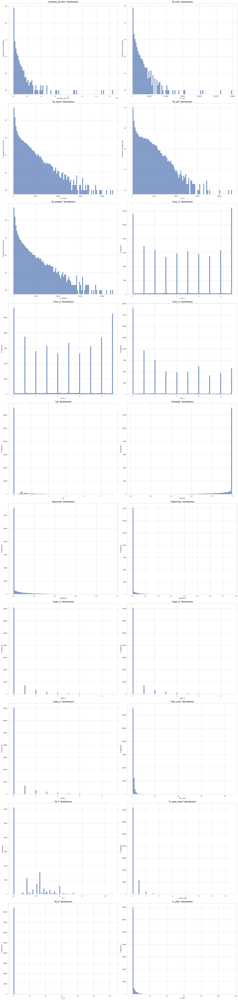

In [14]:
plot_histograms(albedo_filtered[colums_histogram], ncols=2, dataset_name="Albedo Photons")

It is possibile to notice that:
- The energetics centroids are well ditributed across the range ([0, 9])
- The event with number of hits > 1 are mainly *linear* event. 

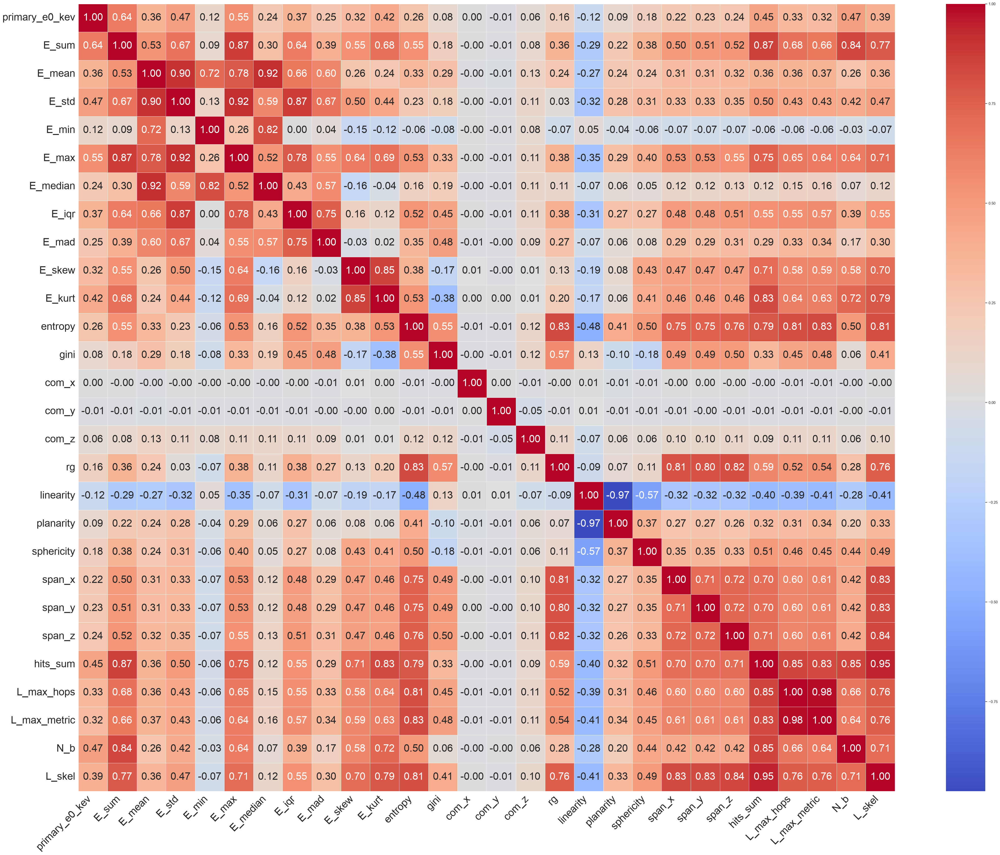

In [15]:
plot_correlation_matrix(albedo_filtered[columns_correlation], dataset_name="Albedo Photons")

Plot the energy spectrum:

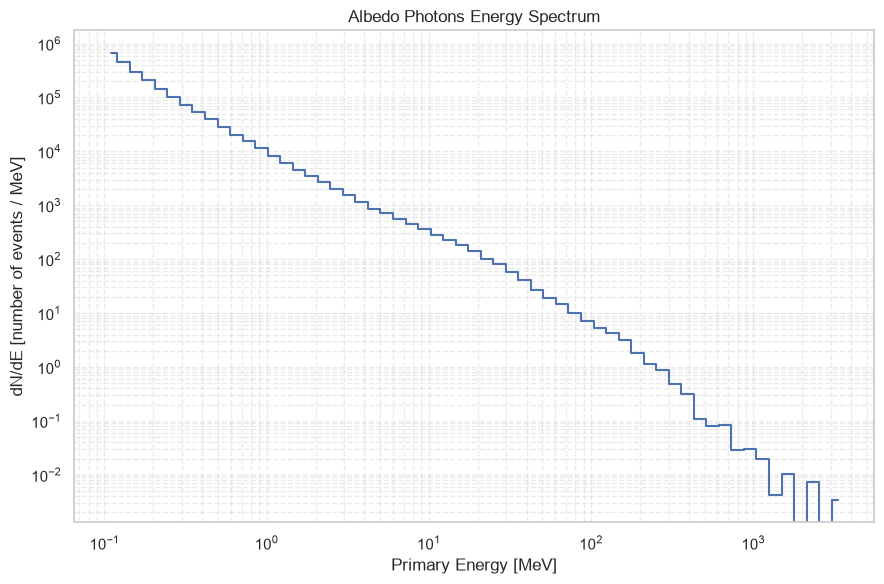

In [16]:
plot_energy_spectrum(albedo_filtered, particle_name="Albedo Photons")

## 1.2 - Atmospheric Neutrons

In [17]:
print("Atmospheric Neutrons dataset shape:", atm_neutrons.shape)
atm_neutrons.describe(include="all")

Atmospheric Neutrons dataset shape: (9962, 54)


,event_index,pixel_ijk,primary_e0_kev,n_voxels,E_sum,E_mean,E_std,E_min,E_max,E_median,E_p10,E_p25,E_p75,E_p90,E_p95,E_p99,E_iqr,E_mad,E_skew,E_kurt,entropy,gini,n_active,frac_active,frac_top1,frac_top3,eff_E_ge_T,com_x,com_y,com_z,rg,lam1,lam2,lam3,linearity,planarity,sphericity,asym_x,asym_y,asym_z,span_x,span_y,span_z,hits_sum,hits_mean_active,corr_E_hits,D_f,D_f_r2,f_occ,L_max_hops,L_max_metric,N_b,L_skel,particle_type
count,9962.000000,9962,9.962000e+03,9962.000000,9962.000000,9962.000000,3723.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,2118.000000,2118.000000,9962.000000,9962.000000,9962.000000,9962.0,9962.000000,9962.000000,9962.0,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9.962000e+03,9962.000000,3723.000000,3.723000e+03,3723.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.000000,9962.0,0.0,3.037000e+03,1858.000000,0.0,9962.000000,9962.000000,9962.000000,9962.000000,9962
unique,NaN,4163,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,NaN,"[6,5,0]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AtmosphericNeutrons
freq,NaN,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9962
mean,22978.648665,NaN,5.264396e+04,2.126882,4569.901833,1483.004590,2661.477569,846.558096,3075.401865,1197.696937,906.328088,1000.675974,1656.170323,2264.128406,2590.455425,2955.910230,655.494350,303.441197,0.629682,-1.156527,0.298365,0.041453,2.126882,1.0,0.872650,0.981769,1.0,4.431611,4.432388,4.342025,0.585530,1.168304,1.198960e-01,0.020828,0.888015,9.365360e-02,0.018331,-0.000661,0.003984,0.012709,0.971291,0.991969,1.019374,2.126882,1.0,NaN,3.372934e-01,0.886810,NaN,0.360068,0.431351,0.198253,2.644939,NaN
std,13296.770079,NaN,7.379630e+05,2.874332,24119.418547,4739.397335,6256.650968,3939.029247,11472.973585,4525.887193,3977.395624,4105.063929,5444.981892,6912.768047,8045.279251,10290.287913,2949.169740,1796.800137,0.699102,2.590545,0.481301,0.065711,2.874332,0.0,0.204958,0.065614,0.0,2.842472,2.787274,2.802495,0.982995,2.858316,4.534541e-01,0.109840,0.175769,1.516020e-01,0.049501,0.329735,0.327532,0.328024,1.836336,1.874417,1.909120,2.874332,0.0,NaN,3.306851e-01,0.114687,NaN,0.810621,0.915649,1.562712,5.479007,NaN
min,7.000000,NaN,0.000000e+00,1.000000,15.001710,15.001710,0.008818,15.001710,15.001710,15.001710,15.001710,15.001710,15.001710,15.001710,15.001710,15.001710,0.000000,0.000000,-0.892694,-2.436473,-0.000000,0.000000,1.000000,1.0,0.128067,0.279978,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.034753,0.000000e+00,0.000000,-0.999349,-0.999281,-0.999294,0.000000,0.000000,0.000000,1.000000,1.0,NaN,-1.057477e-16,0.600000,NaN,0.000000,0.000000,0.000000,0.000000,NaN
25%,11492.500000,NaN,6.642983e+02,1.000000,65.430093,54.503677,62.441270,34.115625,58.963670,52.689185,42.043329,47.267818,56.824317,58.299512,58.744350,58.922288,0.000000,0.000000,0.247653,-2.333333,0.000000,0.000000,1.000000,1.0,0.762060,1.000000,1.0,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000e+00,0.000000,0.840836,1.474908e-18,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.0,NaN,2.397574e-16,0.750000,NaN,0.000000,0.000000,0.000000,0.000000,NaN
50%,23015.500000,NaN,2.952985e+03,1.000000,206.249510,154.822862,292.730116,79.578245,182.253800,139.835895,94.237953,113.641554,167.606625,176.703804,179.966017,182.008720,0.000000,0.000000,0.426222,-1.823683,-0.000000,0.000000,1.000000,1.0,1.000000,1.000000,1.

As before the problem of `frac_active` feature is present. 

In [18]:
print(f"\nThe number of missing values in each column of the filtered Atmospheric Neutrons dataset is:")
atm_neutrons.isnull().sum()[atm_neutrons.isnull().sum() > 0]


The number of missing values in each column of the filtered Atmospheric Neutrons dataset is:


E_std          6239
E_skew         7844
E_kurt         7844
linearity      6239
planarity      6239
sphericity     6239
corr_E_hits    9962
D_f            6925
D_f_r2         8104
f_occ          9962
dtype: int64

Same analisys as before for the missing values: high quantity of 1-hit event.

In [19]:
atm_neutrons_filtered = atm_neutrons.drop(columns=["f_occ", "frac_active"], )
atm_neutrons_filtered.shape

(9962, 52)

Now the values are plotted as histogram in order to visualize their distribution:

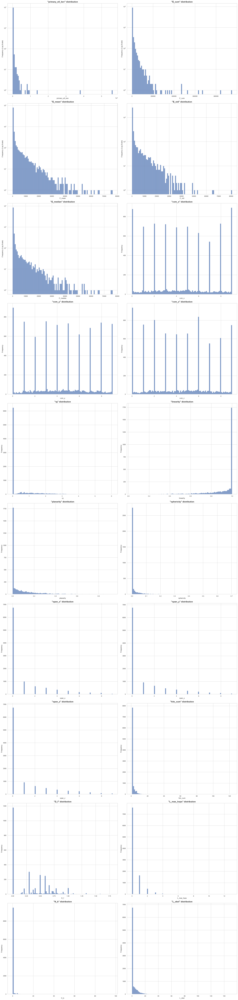

In [20]:
plot_histograms(atm_neutrons[colums_histogram], ncols=2, n_bins=100)

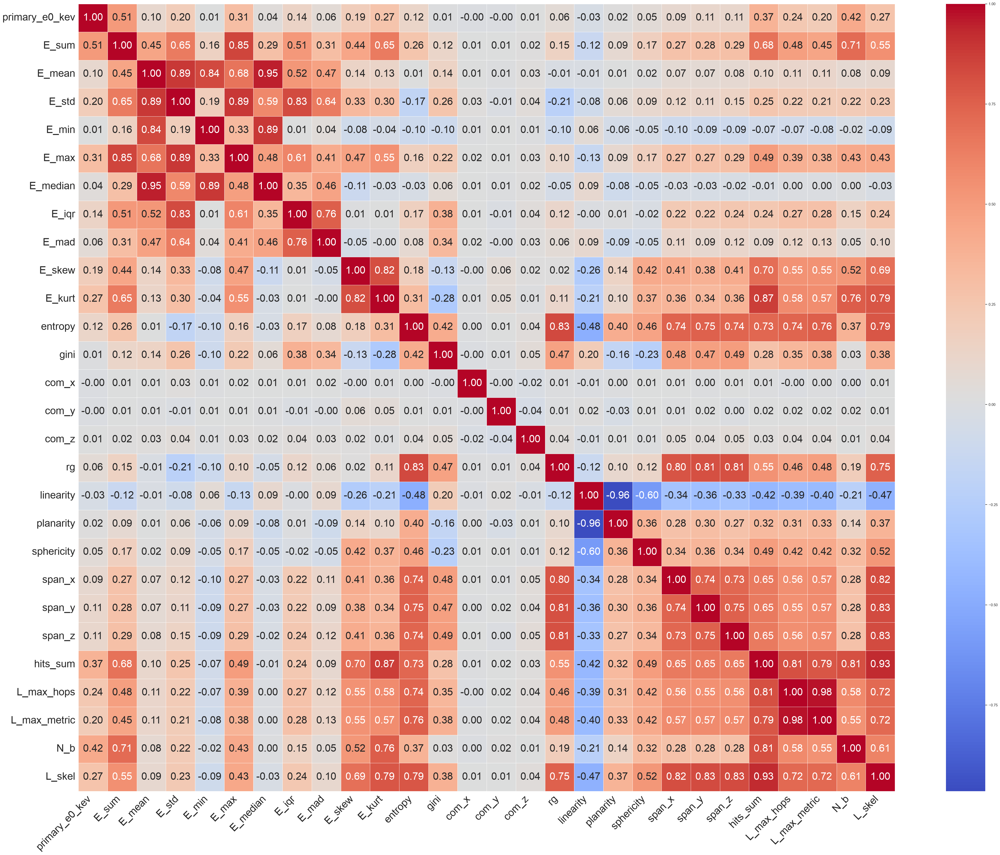

In [21]:
plot_correlation_matrix(atm_neutrons_filtered[columns_correlation], dataset_name="Atmospheric Neutrons")

Plot the energy spectrum:

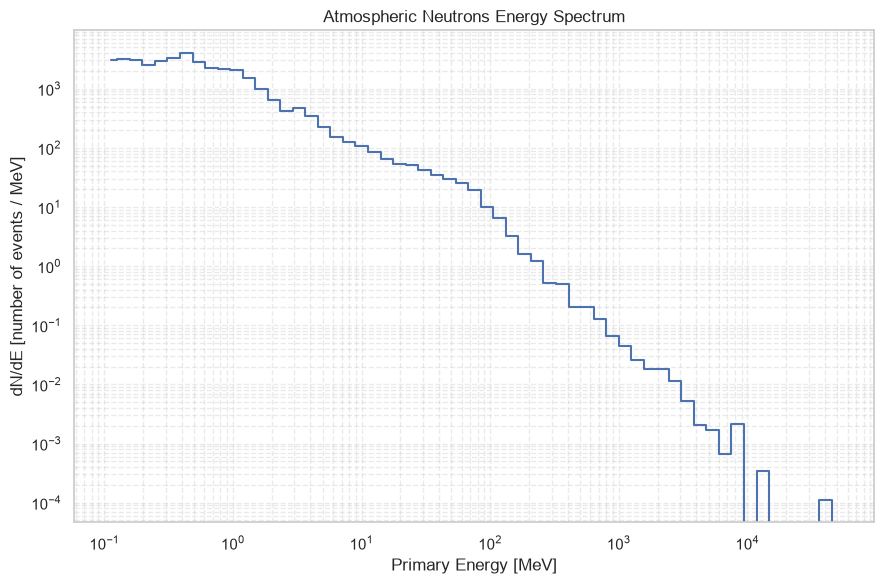

In [22]:
plot_energy_spectrum(atm_neutrons_filtered, particle_name="Atmospheric Neutrons")

## 1.3 - Cosmic Photons

In [23]:
print("Cosmic Photons dataset shape:", cosmic_pht.shape)
cosmic_pht.describe(include="all").T

Cosmic Photons dataset shape: (152860, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,152860.0,NaN,NaN,NaN,145352.302545,83855.186349,3.0,72898.75,145456.0,217927.25,290301.0
pixel_ijk,152860,9888,"[9,9,9]",941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,152860.0,NaN,NaN,NaN,231.236167,2705.006742,100.0,116.28875,142.965,201.36725,912588.394
n_voxels,152860.0,NaN,NaN,NaN,1.118082,0.410773,1.0,1.0,1.0,1.0,31.0
E_sum,152860.0,NaN,NaN,NaN,195.295871,669.984098,15.00616,112.838243,138.189125,191.45893,144073.95057
E_mean,152860.0,NaN,NaN,NaN,166.644821,170.479386,15.00616,109.631618,133.268865,179.882463,9124.12578
E_std,15384.0,NaN,NaN,NaN,131.641676,399.982341,0.003062,26.008498,57.801281,116.191977,9338.13049
E_min,152860.0,NaN,NaN,NaN,157.14284,144.654671,15.00122,107.61281,130.592795,175.851642,9124.12578
E_max,152860.0,NaN,NaN,NaN,179.449443,327.722862,15.00616,111.064535,135.906685,185.642097,37940.80855
E_median,152860.0,NaN,NaN,NaN,165.088411,160.761315,15.00616,109.551992,133.174175,179.639333,9124.12578


In [24]:
print(f"\nThe number of missing values in each column of the filtered Cosmic Photons dataset is:")
cosmic_pht.isnull().sum()[cosmic_pht.isnull().sum() > 0]


The number of missing values in each column of the filtered Cosmic Photons dataset is:


E_std          137476
E_skew         150935
E_kurt         150935
linearity      137476
planarity      137476
sphericity     137476
corr_E_hits    152860
D_f            146235
D_f_r2         151547
f_occ          152860
dtype: int64

In [25]:
cosmic_pht_filtered = cosmic_pht.drop(columns=["f_occ", "frac_active"])
cosmic_pht_filtered.shape

(152860, 52)

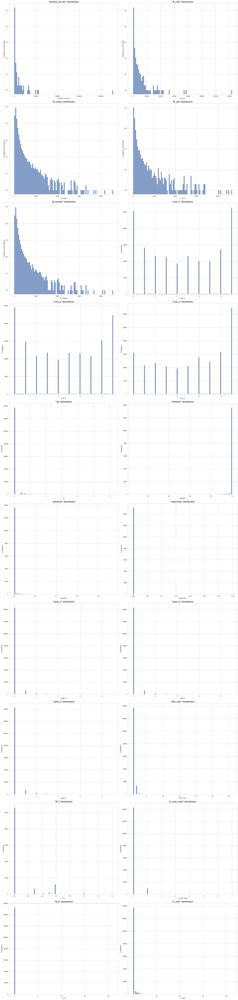

In [26]:
plot_histograms(cosmic_pht[colums_histogram], ncols=2, n_bins=100)

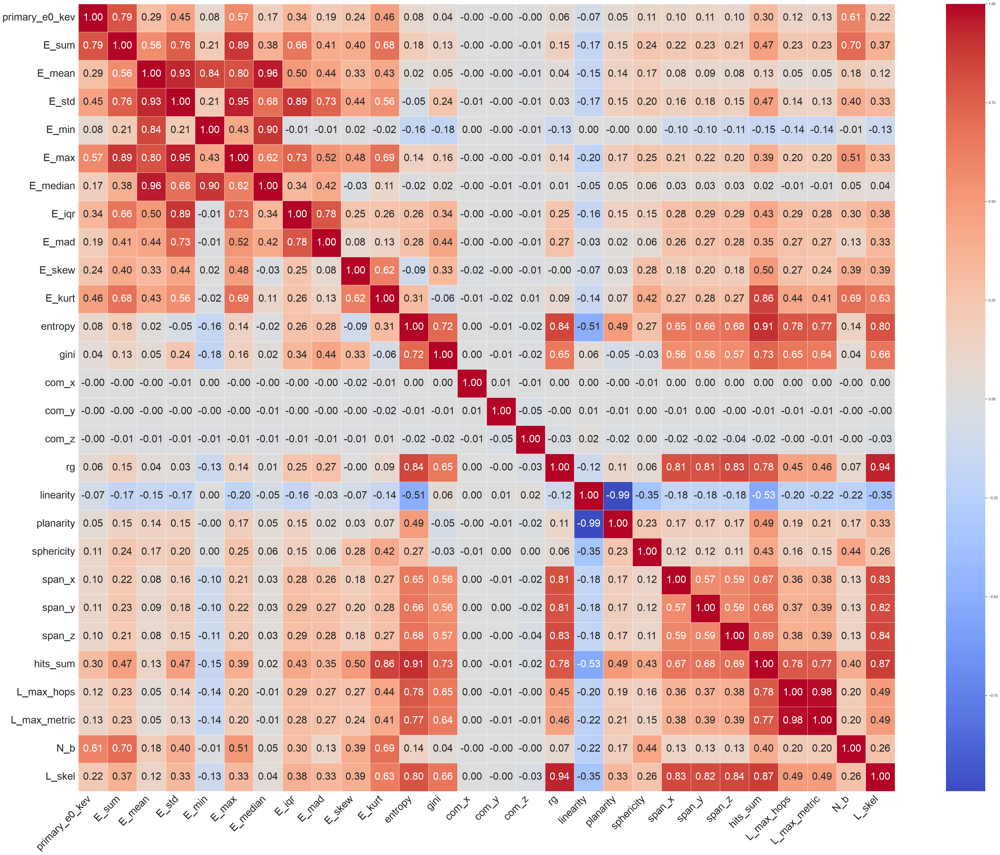

In [27]:
plot_correlation_matrix(cosmic_pht_filtered[columns_correlation], dataset_name="Cosmic Photons")

Plot the energy spectrum:

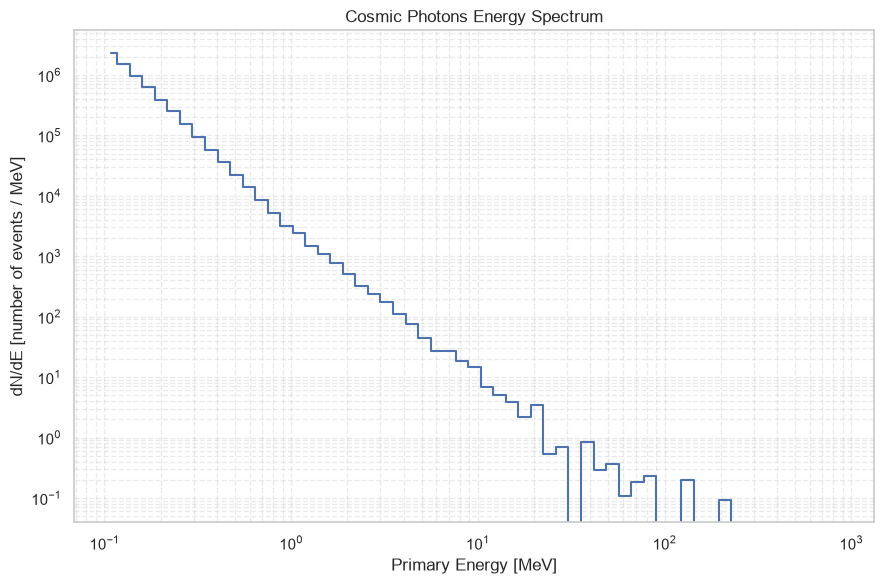

In [28]:
plot_energy_spectrum(cosmic_pht_filtered, particle_name="Cosmic Photons")

## 1.4 - Primary Alphas

In [29]:
print("Primary Alphas dataset shape:", prim_alphas.shape)
prim_alphas.describe(include="all").T

Primary Alphas dataset shape: (11677, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,11677.0,NaN,NaN,NaN,9338.573007,5377.999042,1.0,4687.0,9341.0,14004.0,18604.0
pixel_ijk,11677,9081,"[9,9,9]",44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,11677.0,NaN,NaN,NaN,41541327.241,101158656.722339,0.0,16513557.761,25870520.534,42192778.903,4168141991.329
n_voxels,11677.0,NaN,NaN,NaN,14.017299,30.436139,1.0,2.0,5.0,11.0,371.0
E_sum,11677.0,NaN,NaN,NaN,238776.384687,601869.994305,15.34799,8639.69912,80634.02973,174267.15624,10401215.14334
E_mean,11677.0,NaN,NaN,NaN,14125.080784,10997.035013,15.34799,5454.98387,14160.494589,20230.10576,180651.803577
E_std,8891.0,NaN,NaN,NaN,20869.238143,23105.11264,0.301348,12046.974726,15958.304493,20053.755647,348505.616773
E_min,11677.0,NaN,NaN,NaN,3533.027749,8422.782285,15.00539,43.0603,155.09982,1311.01351,139594.53465
E_max,11677.0,NaN,NaN,NaN,74812.591972,175544.57535,15.34799,7658.98788,36864.15245,46185.90777,2084686.21002
E_median,11677.0,NaN,NaN,NaN,10320.88806,11256.543393,15.34799,932.36983,5891.47808,17223.05643,139594.53465


In [30]:
print(f"\nThe number of missing values in each column of the filtered Primary Alphas dataset is:")
prim_alphas.isnull().sum()[prim_alphas.isnull().sum() > 0]


The number of missing values in each column of the filtered Primary Alphas dataset is:


E_std           2786
E_skew          4047
E_kurt          4047
linearity       2786
planarity       2786
sphericity      2786
corr_E_hits    11677
D_f             3840
D_f_r2          4428
f_occ          11677
dtype: int64

In [31]:
prim_alphas_filtered = prim_alphas.drop(columns=["f_occ", "frac_active"], )
prim_alphas_filtered.shape

(11677, 52)

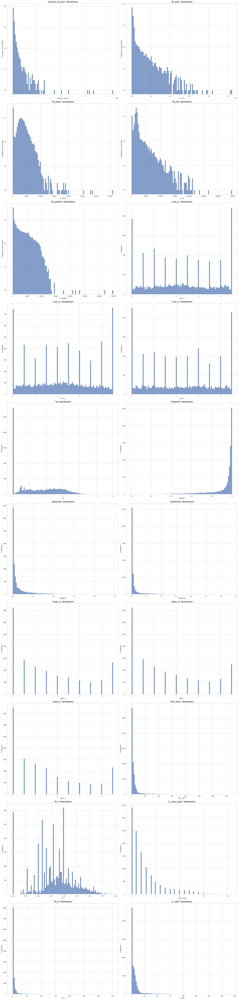

In [32]:
plot_histograms(prim_alphas_filtered[colums_histogram], ncols=2, n_bins=100)

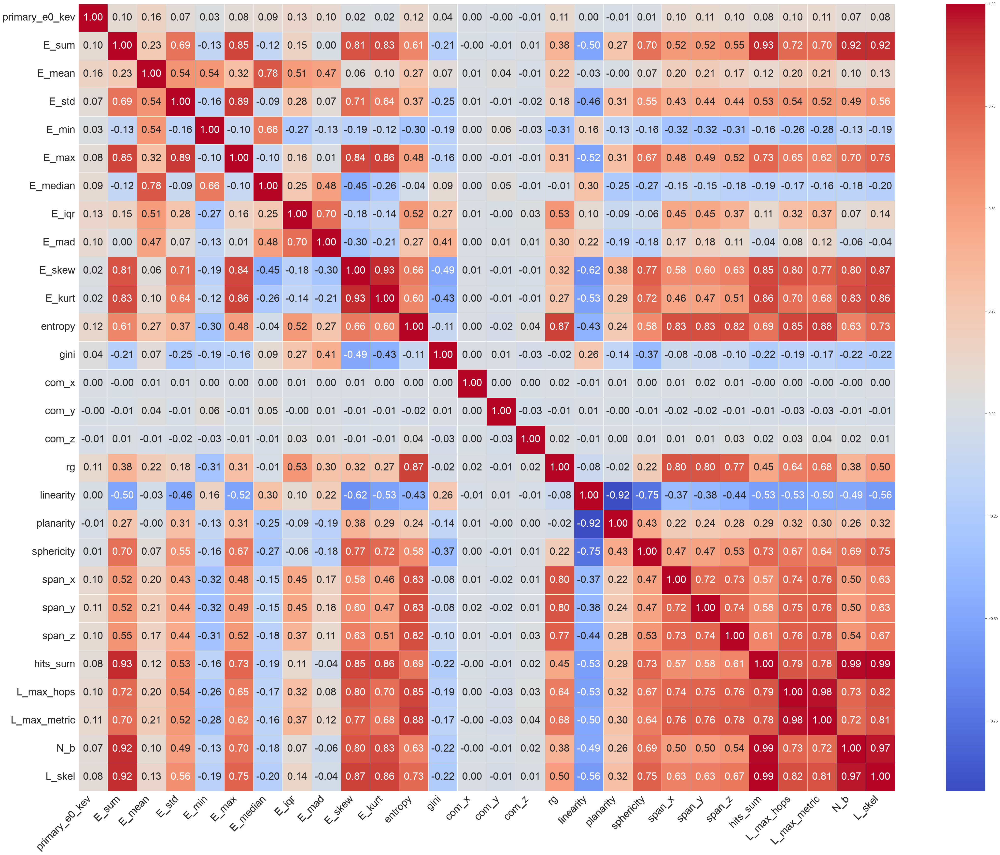

In [33]:
plot_correlation_matrix(prim_alphas_filtered[columns_correlation], dataset_name="Primary Alphas")

Plot the energy spectrum:

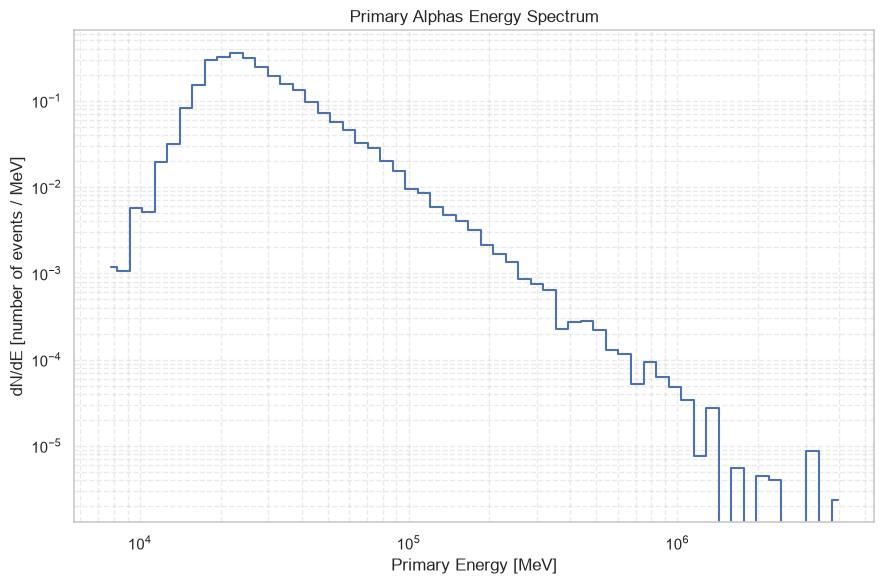

In [34]:
plot_energy_spectrum(prim_alphas_filtered, particle_name="Primary Alphas")

## 1.5 - Primary Electrons

In [35]:
print("Primary Electrons dataset shape:", prim_electrons.shape)
prim_electrons.describe(include="all").T

Primary Electrons dataset shape: (8537, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,8537.0,NaN,NaN,NaN,7338.792433,4229.431975,3.0,3685.0,7321.0,11018.0,14673.0
pixel_ijk,8537,7404,"[9,9,9]",37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,8537.0,NaN,NaN,NaN,16198156.076464,18636135.127329,0.0,9283308.865,12752929.517,17812979.184,484240603.918
n_voxels,8537.0,NaN,NaN,NaN,34.441724,43.002162,1.0,3.0,16.0,52.0,293.0
E_sum,8537.0,NaN,NaN,NaN,407804.208982,638703.507788,17.86267,19294.29646,143769.5691,538330.47289,8412406.23131
E_mean,8537.0,NaN,NaN,NaN,9385.763517,5869.792634,17.86267,5649.823814,8878.593678,12436.378106,55320.9781
E_std,7200.0,NaN,NaN,NaN,25099.675924,19758.51702,0.417349,10784.584671,20887.225105,34920.324732,239119.222395
E_min,8537.0,NaN,NaN,NaN,1126.338381,3265.469628,15.00215,25.09824,43.0603,258.84714,52566.20974
E_max,8537.0,NaN,NaN,NaN,119178.237869,157583.116748,17.86267,13119.79436,59611.3572,169114.81711,2292673.77361
E_median,8537.0,NaN,NaN,NaN,2683.494225,4330.650979,17.86267,510.99891,796.27251,3009.128465,55320.9781


In [36]:
print(f"\nThe number of missing values in each column of the filtered Primary Electrons dataset is:")
prim_electrons.isnull().sum()[prim_electrons.isnull().sum() > 0]


The number of missing values in each column of the filtered Primary Electrons dataset is:


E_std          1337
E_skew         2017
E_kurt         2017
linearity      1337
planarity      1337
sphericity     1337
corr_E_hits    8537
D_f            1926
D_f_r2         2212
f_occ          8537
dtype: int64

In [37]:
prim_electrons_filtered = prim_electrons.drop(columns=["f_occ", "frac_active"], )
prim_electrons_filtered.shape

(8537, 52)

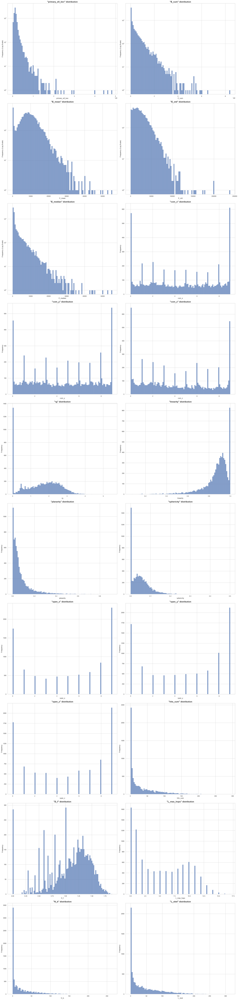

In [38]:
plot_histograms(prim_electrons_filtered[colums_histogram], ncols=2, n_bins=100)

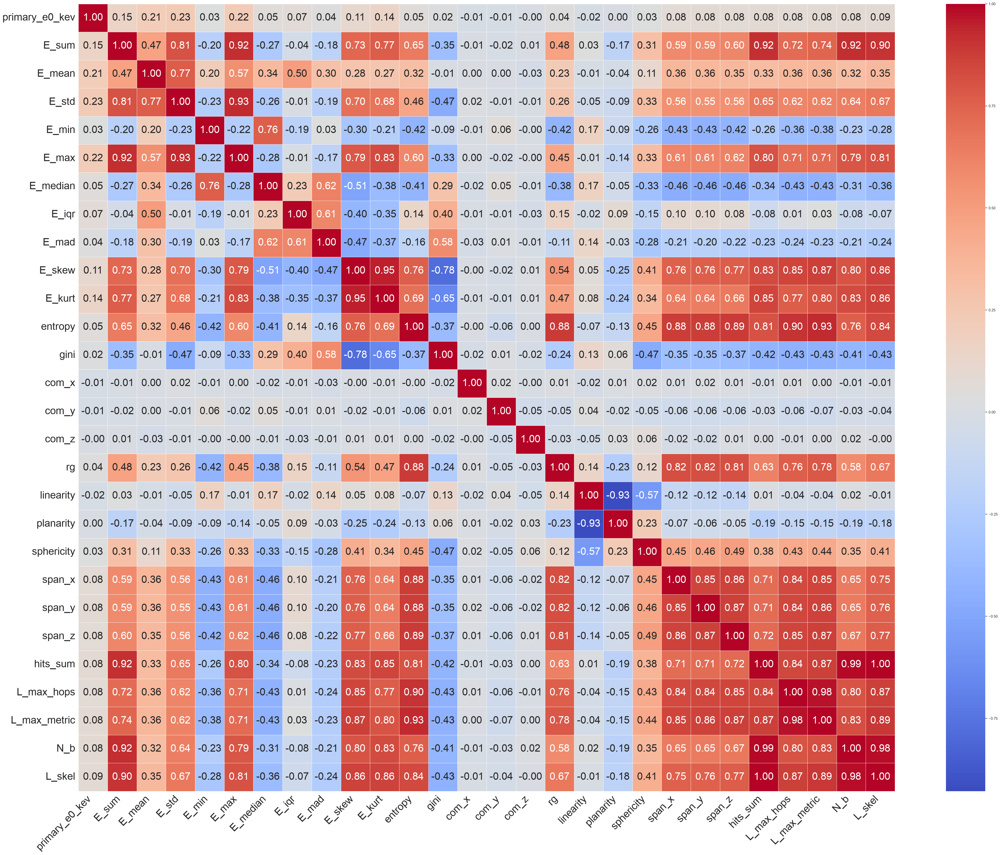

In [39]:
plot_correlation_matrix(prim_electrons_filtered[columns_correlation], dataset_name="Primary Electrons")

Plot the energy spectrum:

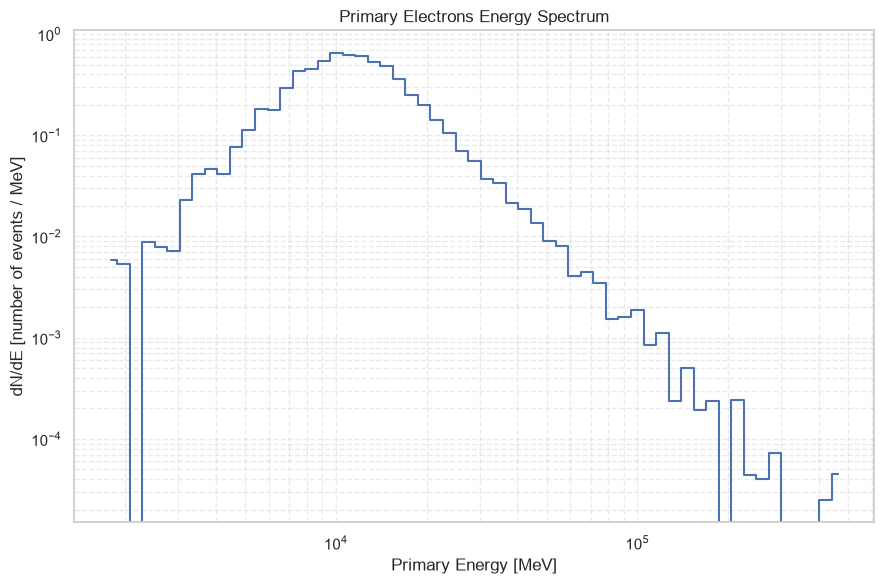

In [40]:
plot_energy_spectrum(prim_electrons_filtered, particle_name="Primary Electrons")

## 1.6 - Primary Positron

In [41]:
print("Primary Positrons dataset shape:", prim_positrons.shape)
prim_positrons.describe(include="all").T

Primary Positrons dataset shape: (19636, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,19636.0,NaN,NaN,NaN,16485.38903,9579.825478,1.0,8167.75,16445.5,24779.25,33165.0
pixel_ijk,19636,16176,"[9,9,9]",86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,19636.0,NaN,NaN,NaN,18886460.028137,27748270.130904,0.0,9417312.85825,13251038.811,19845221.72725,873982181.995
n_voxels,19636.0,NaN,NaN,NaN,33.550367,43.398167,1.0,2.0,14.0,50.0,358.0
E_sum,19636.0,NaN,NaN,NaN,409899.028623,715201.719915,15.07898,16434.08964,125891.841285,516988.876217,15872347.0856
E_mean,19636.0,NaN,NaN,NaN,9322.004412,6218.544999,15.07898,5340.814825,8741.951959,12490.769131,74480.56363
E_std,16240.0,NaN,NaN,NaN,25703.885116,21655.34956,0.301348,10523.049148,20884.104646,35404.524344,332000.714829
E_min,19636.0,NaN,NaN,NaN,1150.912648,3442.684164,15.00029,25.72561,43.0603,273.794225,74480.56363
E_max,19636.0,NaN,NaN,NaN,121508.906675,180520.11912,15.07898,11732.948,56386.036485,168499.035613,4791314.74124
E_median,19636.0,NaN,NaN,NaN,2656.815299,4449.5415,15.07898,510.99891,775.98706,2886.245889,74480.56363


In [42]:
print(f"\nThe number of missing values in each column of the filtered Primary Positrons dataset is:")
prim_positrons.isnull().sum()[prim_positrons.isnull().sum() > 0]


The number of missing values in each column of the filtered Primary Positrons dataset is:


E_std           3396
E_skew          4942
E_kurt          4942
linearity       3396
planarity       3396
sphericity      3396
corr_E_hits    19636
D_f             4681
D_f_r2          5349
f_occ          19636
dtype: int64

In [43]:
prim_positrons_filtered = prim_positrons.drop(columns=["f_occ", "frac_active"], )
prim_positrons_filtered.shape

(19636, 52)

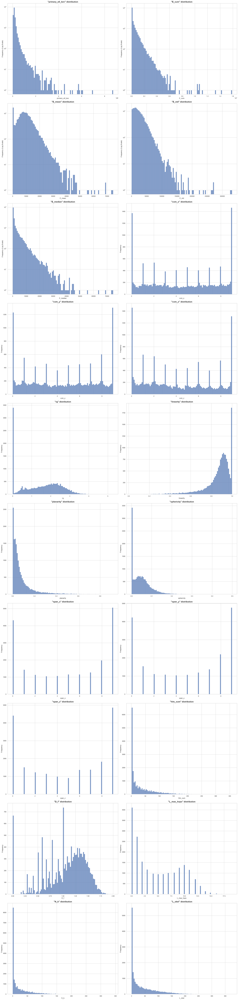

In [44]:
plot_histograms(prim_positrons_filtered[colums_histogram], ncols=2, n_bins=100)

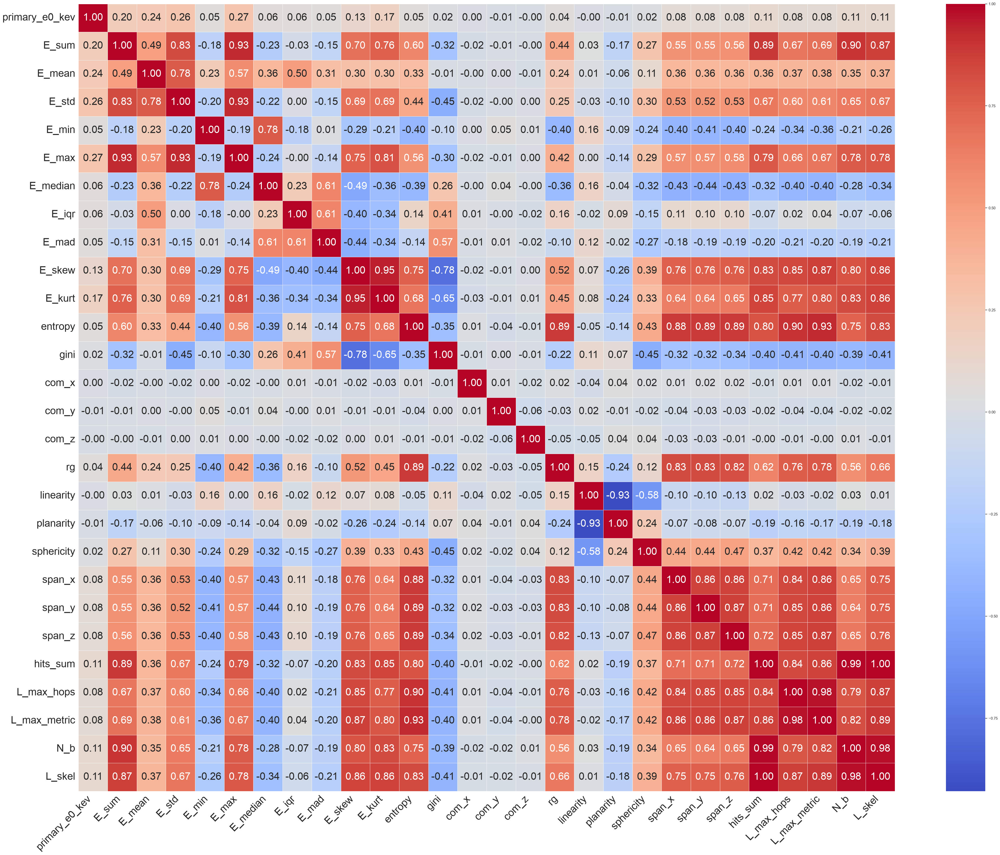

In [45]:
plot_correlation_matrix(prim_positrons_filtered[columns_correlation], dataset_name="Primary Positrons")

Plot the energy spectrum:

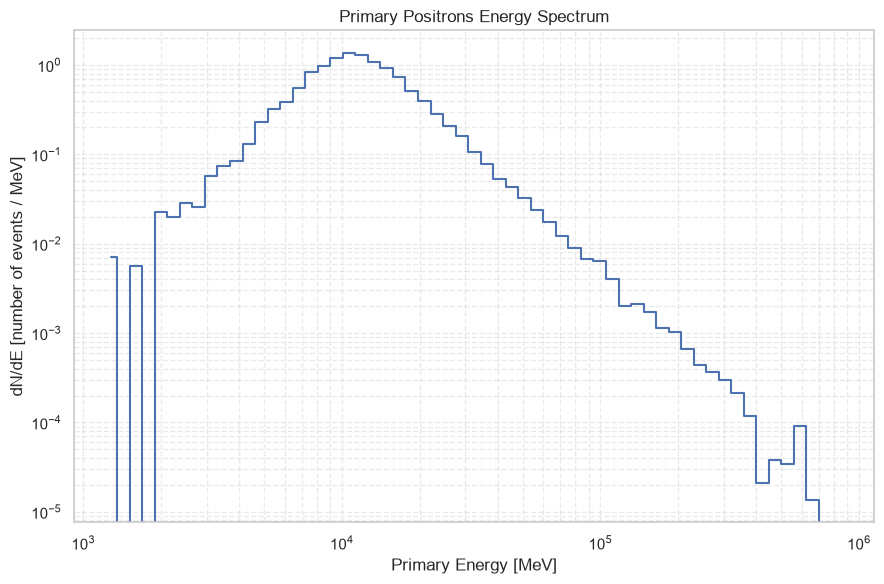

In [46]:
plot_energy_spectrum(prim_positrons_filtered, particle_name="Primary Positrons")

## 1.7 - Primary Protons

In [47]:
print("Primary Protons dataset shape:", prim_protons.shape)
prim_protons.describe(include="all").T

Primary Protons dataset shape: (18461, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,18461.0,NaN,NaN,NaN,15403.170305,8894.994895,1.0,7675.0,15445.0,23149.0,30741.0
pixel_ijk,18461,14448,"[9,9,9]",81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,18461.0,NaN,NaN,NaN,21187399.003714,75526108.50869,0.0,10832824.0,14419002.438,21690110.178,8247294571.619
n_voxels,18461.0,NaN,NaN,NaN,9.416066,18.916254,1.0,2.0,5.0,8.0,280.0
E_sum,18461.0,NaN,NaN,NaN,95013.387125,281310.540896,16.12849,9360.88047,24727.96183,46160.74348,6863303.77455
E_mean,18461.0,NaN,NaN,NaN,6201.177046,5856.140088,16.12849,3815.919815,5410.760876,7187.055068,187533.45634
E_std,14886.0,NaN,NaN,NaN,8481.088747,15561.959515,1.309548,2885.891095,3942.811822,5418.04466,361687.374836
E_min,18461.0,NaN,NaN,NaN,1768.127592,3594.094137,15.00538,96.60066,510.99891,2273.87904,187533.45634
E_max,18461.0,NaN,NaN,NaN,31594.021587,86742.336157,16.12849,6845.07723,9749.4047,12764.8925,1504260.70102
E_median,18461.0,NaN,NaN,NaN,4626.121657,3961.888947,16.12849,2182.64846,4497.6862,6678.369015,187533.45634


In [48]:
print(f"\nThe number of missing values in each column of the filtered Primary Protons dataset is:")
prim_protons.isnull().sum()[prim_protons.isnull().sum() > 0]


The number of missing values in each column of the filtered Primary Protons dataset is:


E_std           3575
E_skew          5710
E_kurt          5710
linearity       3575
planarity       3575
sphericity      3575
corr_E_hits    18461
D_f             5445
D_f_r2          6395
f_occ          18461
dtype: int64

In [49]:
prim_protons_filtered = prim_protons.drop(columns=["f_occ", "frac_active"], )
prim_protons_filtered.shape

(18461, 52)

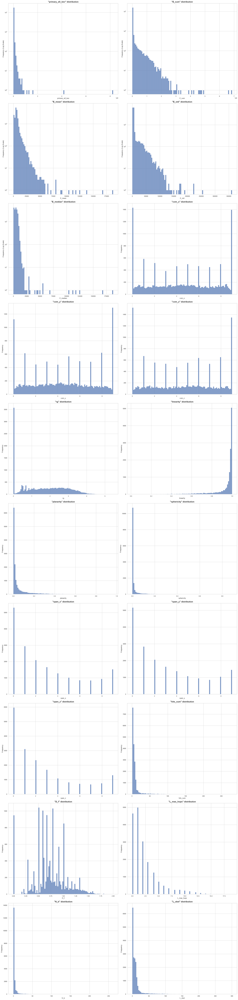

In [50]:
plot_histograms(prim_protons_filtered[colums_histogram], ncols=2, n_bins=100)

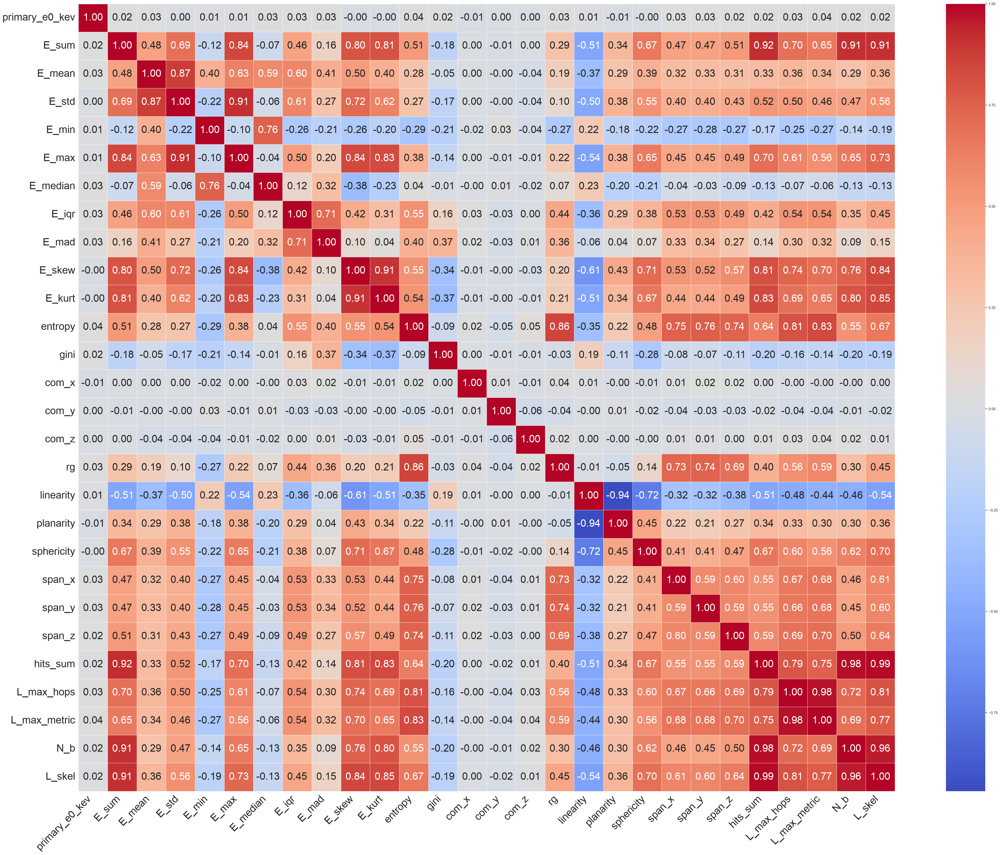

In [51]:
plot_correlation_matrix(prim_protons_filtered[columns_correlation], dataset_name="Primary Protons")

Plot the energy spectrum:

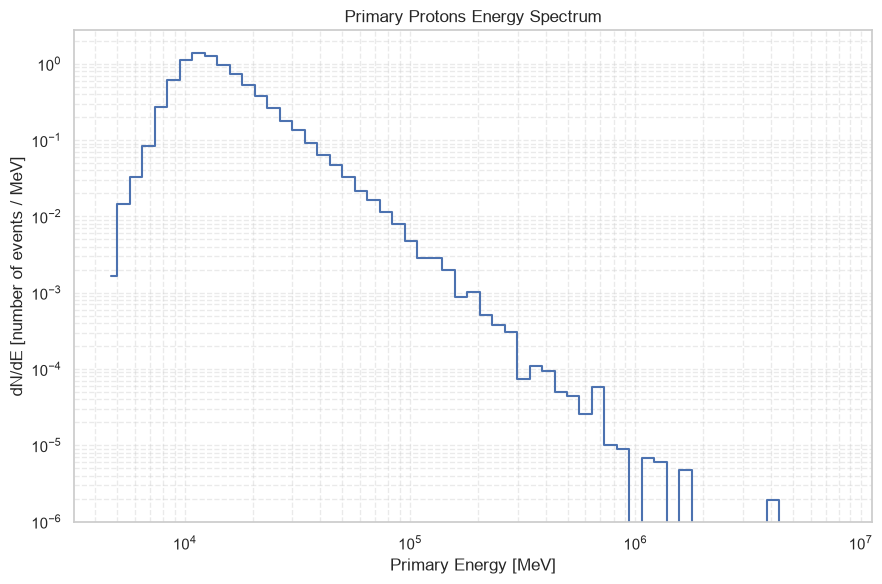

In [52]:
plot_energy_spectrum(prim_protons_filtered, particle_name="Primary Protons")

## 1.8 - Secondary Electrons

In [53]:
print("Secondary Electrons dataset shape:", sec_electrons.shape)
sec_electrons.describe(include="all").T

Secondary Electrons dataset shape: (8730, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,8730.0,NaN,NaN,NaN,7549.99748,4354.487453,1.0,3772.75,7527.5,11320.75,15068.0
pixel_ijk,8730,5675,"[9,9,9]",41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,8730.0,NaN,NaN,NaN,71022.734745,347295.488771,0.0,3948.79175,15237.4815,58577.97125,23036013.909
n_voxels,8730.0,NaN,NaN,NaN,5.193013,7.485731,1.0,1.0,2.0,6.0,155.0
E_sum,8730.0,NaN,NaN,NaN,18825.029251,35847.590709,17.67218,2565.840877,7920.692055,21494.882233,1103697.50972
E_mean,8730.0,NaN,NaN,NaN,3416.731959,2446.361892,17.67218,1675.736919,2942.392745,4506.554524,26361.423212
E_std,5596.0,NaN,NaN,NaN,4004.544246,2757.437493,0.436059,2160.197749,3706.378837,5265.233892,39299.997596
E_min,8730.0,NaN,NaN,NaN,1533.305175,2393.294834,15.00763,88.953033,368.184955,1978.864125,20375.95351
E_max,8730.0,NaN,NaN,NaN,8079.263206,9026.579182,17.67218,2321.669592,6191.609255,10929.93669,196905.46028
E_median,8730.0,NaN,NaN,NaN,2641.025689,2585.920609,17.67218,748.486295,1766.33943,3709.402525,22582.14227


In [54]:
print(f"\nThe number of missing values in each column of the filtered Secondary Electrons dataset is:")
sec_electrons.isnull().sum()[sec_electrons.isnull().sum() > 0]


The number of missing values in each column of the filtered Secondary Electrons dataset is:


E_std          3134
E_skew         4523
E_kurt         4523
linearity      3134
planarity      3134
sphericity     3134
corr_E_hits    8730
D_f            4331
D_f_r2         4909
f_occ          8730
dtype: int64

In [55]:
sec_electrons_filtered = sec_electrons.drop(columns=["f_occ", "frac_active"], )
sec_electrons_filtered.shape

(8730, 52)

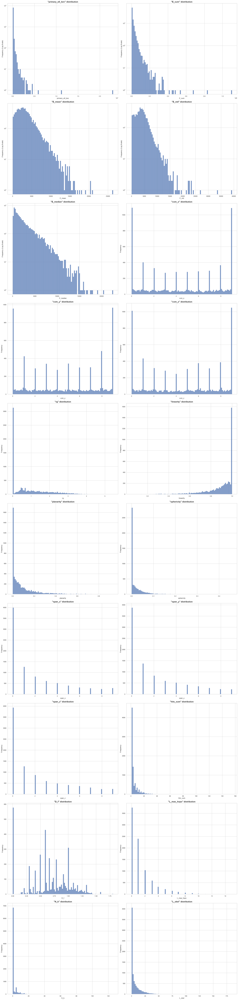

In [56]:
plot_histograms(sec_electrons[colums_histogram], ncols=2, n_bins=100)

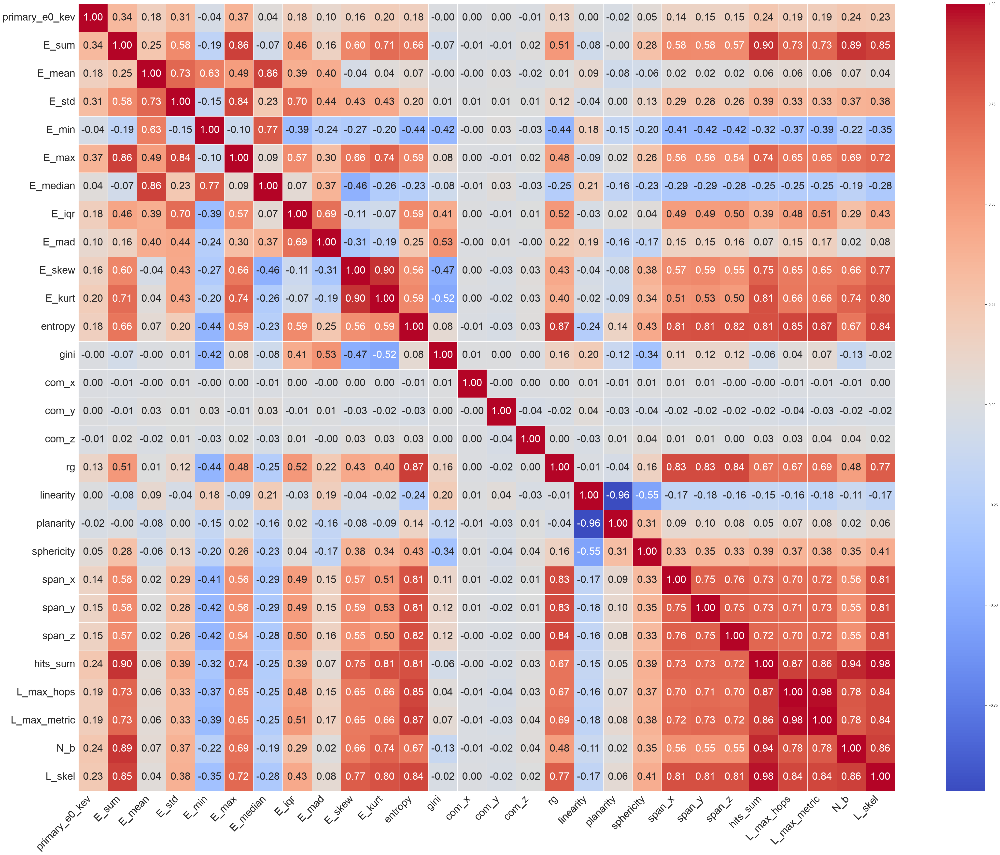

In [57]:
plot_correlation_matrix(sec_electrons_filtered[columns_correlation], dataset_name="Secondary Electrons")

Plot the energy spectrum:

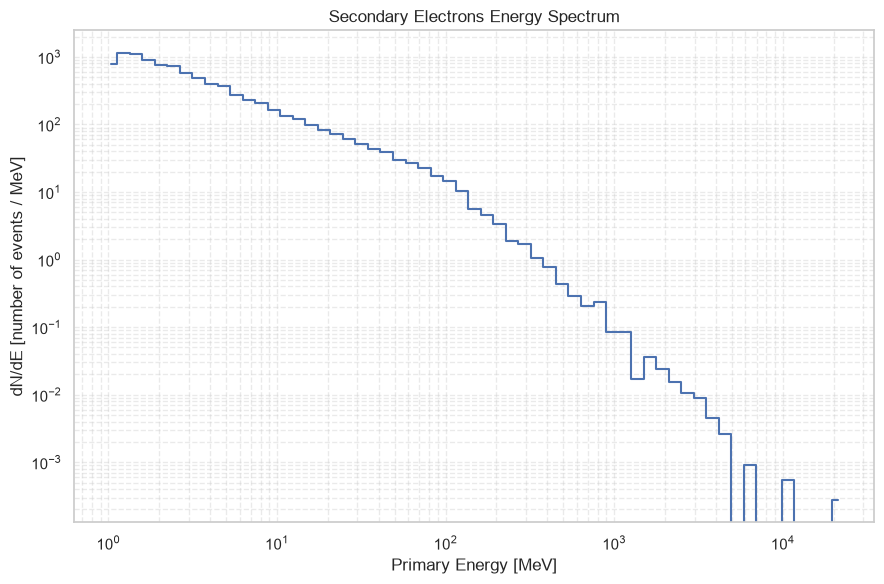

In [58]:
plot_energy_spectrum(sec_electrons_filtered, particle_name="Secondary Electrons")

## 1.9 - Secondary Positrons

In [59]:
print("Secondary Positrons dataset shape:", sec_positrons.shape)
sec_positrons.describe(include="all").T

Secondary Positrons dataset shape: (29089, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,29089.0,NaN,NaN,NaN,24771.326137,14321.659215,1.0,12364.0,24821.0,37163.0,49608.0
pixel_ijk,29089,20661,"[9,9,9]",141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,29089.0,NaN,NaN,NaN,69090.684351,270096.142831,0.0,3896.166,14993.37,59370.304,23036013.909
n_voxels,29089.0,NaN,NaN,NaN,5.798721,7.363655,1.0,2.0,3.0,7.0,132.0
E_sum,29089.0,NaN,NaN,NaN,18593.039656,33424.746827,15.32143,2787.15525,8038.82578,20964.94221,916604.69827
E_mean,29089.0,NaN,NaN,NaN,2963.28596,2277.511759,15.32143,1341.154362,2497.328109,3910.373443,39660.7751
E_std,22062.0,NaN,NaN,NaN,3507.693191,2538.668393,1.052825,1631.884843,3229.244724,4704.996886,34648.258972
E_min,29089.0,NaN,NaN,NaN,1068.450865,2092.252473,15.00483,60.21483,210.51761,934.36003,39660.7751
E_max,29089.0,NaN,NaN,NaN,7852.650287,8519.173569,15.32143,2299.34337,5968.14936,10597.80219,186395.47881
E_median,29089.0,NaN,NaN,NaN,2092.351662,2374.594397,15.32143,503.26872,1199.013,2820.412855,39660.7751


In [60]:
print(f"\nThe number of missing values in each column of the filtered Secondary Positrons dataset is:")
sec_positrons.isnull().sum()[sec_positrons.isnull().sum() > 0]


The number of missing values in each column of the filtered Secondary Positrons dataset is:


E_std           7027
E_skew         11943
E_kurt         11943
linearity       7027
planarity       7027
sphericity      7027
corr_E_hits    29089
D_f            10714
D_f_r2         13419
f_occ          29089
dtype: int64

In [61]:
sec_positrons_filtered = sec_positrons.drop(columns=["f_occ", "frac_active"], )
sec_positrons_filtered.shape

(29089, 52)

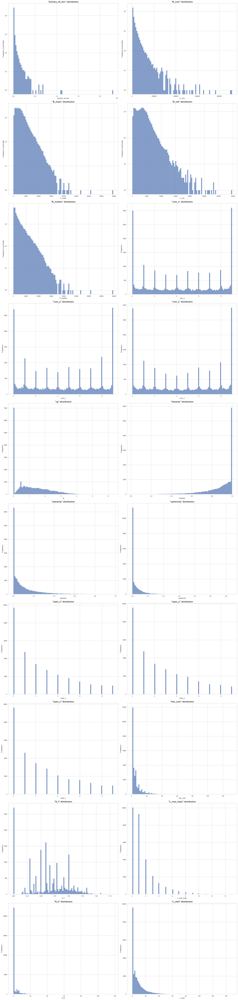

In [62]:
plot_histograms(sec_positrons_filtered[colums_histogram], ncols=2, n_bins=100)

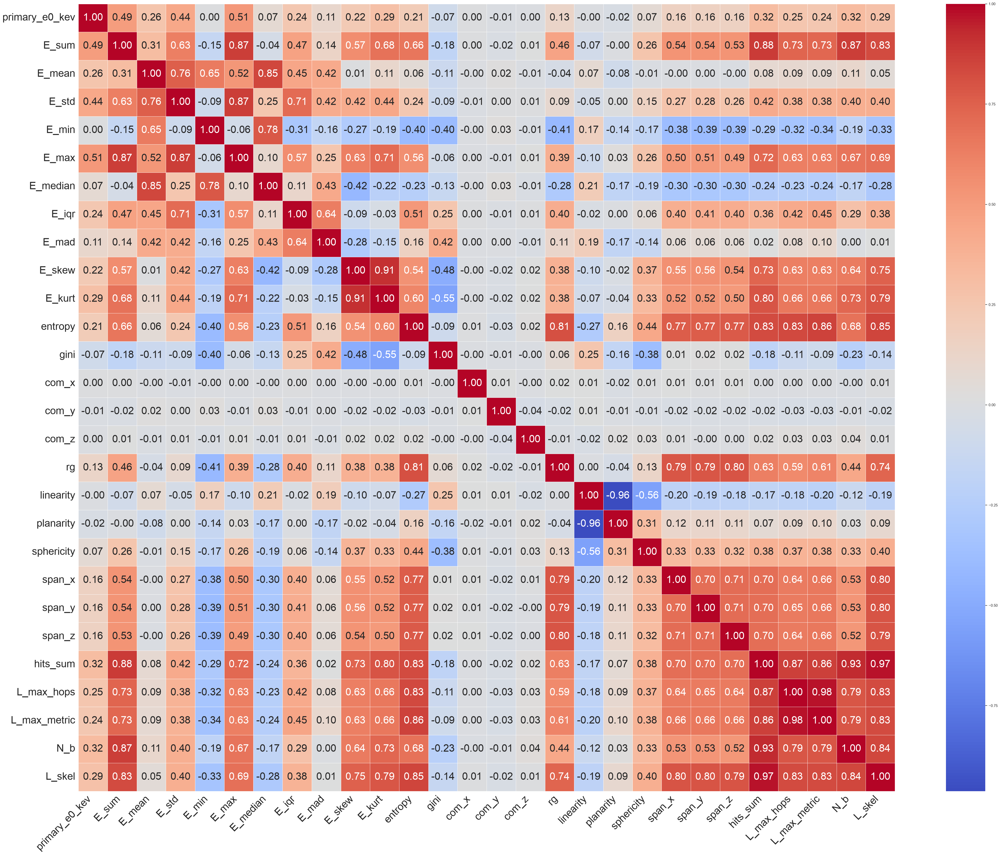

In [63]:
plot_correlation_matrix(sec_positrons_filtered[columns_correlation], dataset_name="Secondary Positrons")

Plot the energy spectrum:

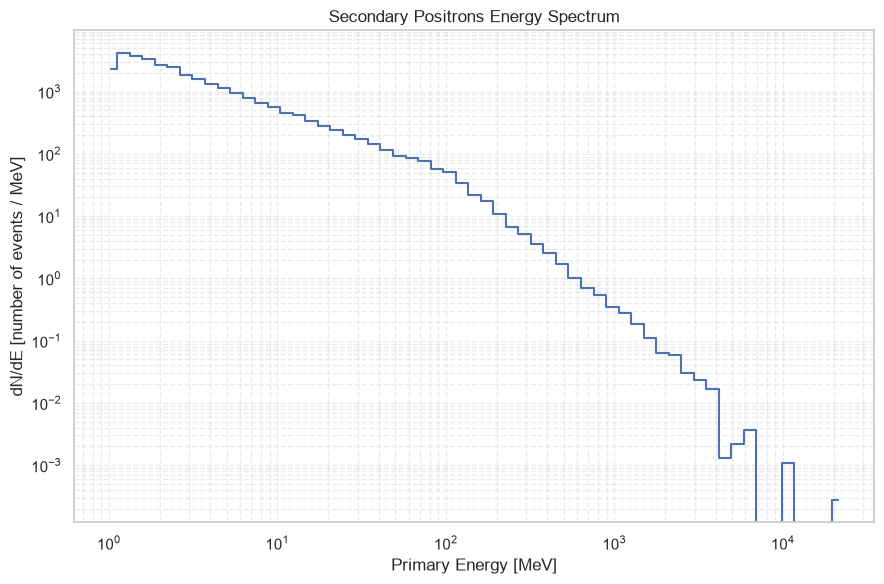

In [64]:
plot_energy_spectrum(sec_positrons_filtered, particle_name="Secondary Positrons")

## 1.10 - Secondary Protons (Downward)

In [65]:
print("Secondary Protons (Downward) dataset shape:", sec_protons_dw.shape)
sec_protons_dw.describe(include="all").T

Secondary Protons (Downward) dataset shape: (11060, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,11060.0,NaN,NaN,NaN,9599.131284,5523.291728,1.0,4836.75,9601.0,14347.25,19160.0
pixel_ijk,11060,5729,"[9,9,9]",65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,11060.0,NaN,NaN,NaN,351328.344617,589428.702069,0.0,8445.49975,88856.765,464897.7135,8326774.446
n_voxels,11060.0,NaN,NaN,NaN,3.313653,4.023362,1.0,1.0,2.0,4.0,90.0
E_sum,11060.0,NaN,NaN,NaN,35626.727963,44257.19922,18.58103,6073.429917,21266.31909,49196.698258,690110.41403
E_mean,11060.0,NaN,NaN,NaN,12169.384537,11986.948753,18.58103,4489.760887,8077.229591,15817.508426,121219.71241
E_std,5574.0,NaN,NaN,NaN,8843.431933,8429.788365,2.673295,3723.086295,5693.848437,11352.954053,86415.993929
E_min,11060.0,NaN,NaN,NaN,8174.22809,11800.371143,15.00727,1000.325345,3415.32325,10214.776275,121219.71241
E_max,11060.0,NaN,NaN,NaN,18342.949221,19897.117274,18.58103,5783.682167,12196.02789,23462.126945,416065.27161
E_median,11060.0,NaN,NaN,NaN,11663.306297,12079.920114,18.58103,3537.38565,7734.172523,15190.572121,121219.71241


In [66]:
print(f"\nThe number of missing values in each column of the filtered Secondary Protons (Downward) dataset is:")
sec_protons_dw.isnull().sum()[sec_protons_dw.isnull().sum() > 0]


The number of missing values in each column of the filtered Secondary Protons (Downward) dataset is:


E_std           5486
E_skew          6746
E_kurt          6746
linearity       5486
planarity       5486
sphericity      5486
corr_E_hits    11060
D_f             6572
D_f_r2          7080
f_occ          11060
dtype: int64

In [67]:
sec_protons_dw_filtered = sec_protons_dw.drop(columns=["f_occ", "frac_active"], )
sec_protons_dw_filtered.shape

(11060, 52)

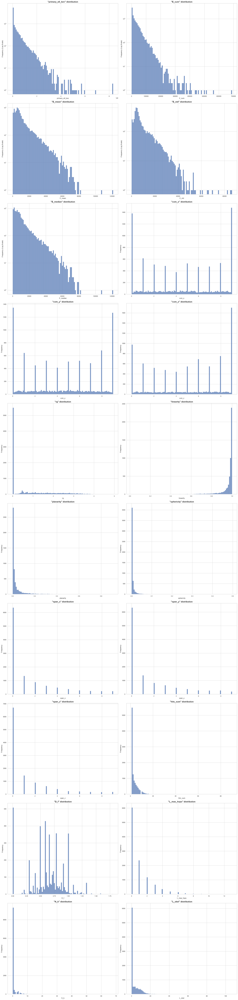

In [68]:
plot_histograms(sec_protons_dw_filtered[colums_histogram], ncols=2, n_bins=100)

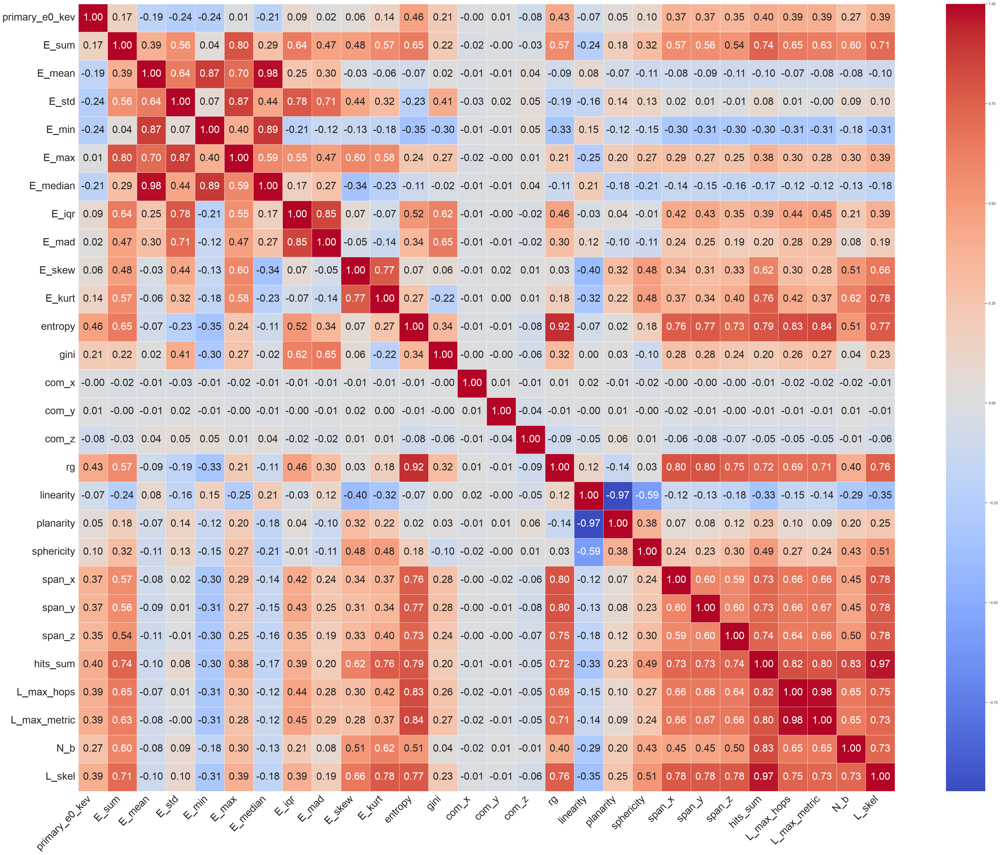

In [69]:
plot_correlation_matrix(sec_protons_dw_filtered[columns_correlation], dataset_name="Secondary Protons (Downward)")

Plot the energy spectrum:

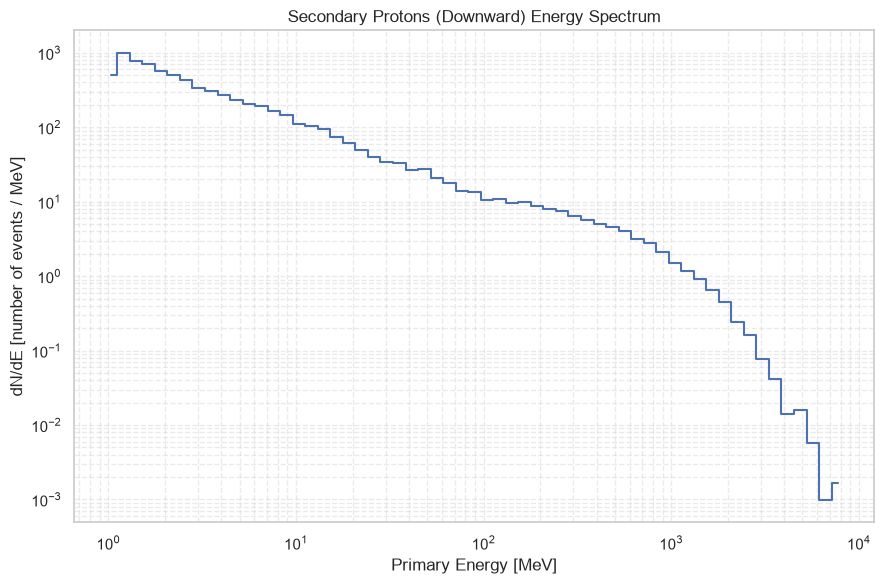

In [70]:
plot_energy_spectrum(sec_protons_dw_filtered, particle_name="Secondary Protons (Downward)")

## 1.11 - Secondary Protons (Upward)

In [71]:
print("Secondary Protons Upward dataset shape:", sec_protons_up.shape)
sec_protons_up.describe(include="all").T

Secondary Protons Upward dataset shape: (11901, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,11901.0,NaN,NaN,NaN,9735.772624,5659.296461,1.0,4830.0,9702.0,14614.0,19579.0
pixel_ijk,11901,6022,"[9,1,0]",74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,11901.0,NaN,NaN,NaN,352707.021386,596029.587824,0.0,8662.362,89665.71,464515.109,10512405.799
n_voxels,11901.0,NaN,NaN,NaN,3.350559,3.828964,1.0,1.0,2.0,5.0,62.0
E_sum,11901.0,NaN,NaN,NaN,34920.533484,42407.112313,18.23119,6041.92712,20535.76735,48715.99474,580991.82228
E_mean,11901.0,NaN,NaN,NaN,11850.308694,11608.436805,18.23119,4345.30352,7844.86107,15316.35246,97626.66373
E_std,5999.0,NaN,NaN,NaN,8665.931572,8460.217505,2.008933,3566.183463,5492.620945,11071.230933,178883.814883
E_min,11901.0,NaN,NaN,NaN,7929.724261,11476.914235,15.00135,1031.10489,3272.52547,9910.08272,97626.66373
E_max,11901.0,NaN,NaN,NaN,17963.262569,19627.413208,18.23119,5626.80077,11805.98523,22894.05911,359168.09665
E_median,11901.0,NaN,NaN,NaN,11356.621451,11695.789847,18.23119,3553.99618,7439.22852,14658.6244,97626.66373


In [72]:
print(f"\nThe number of missing values in each column of the filtered Secondary Protons (Upward) dataset is:")
sec_protons_up.isnull().sum()[sec_protons_up.isnull().sum() > 0]


The number of missing values in each column of the filtered Secondary Protons (Upward) dataset is:


E_std           5902
E_skew          7249
E_kurt          7249
linearity       5902
planarity       5902
sphericity      5902
corr_E_hits    11901
D_f             7138
D_f_r2          7651
f_occ          11901
dtype: int64

In [73]:
sec_protons_up_filtered = sec_protons_up.drop(columns=["f_occ", "frac_active"], )
sec_protons_up_filtered.shape

(11901, 52)

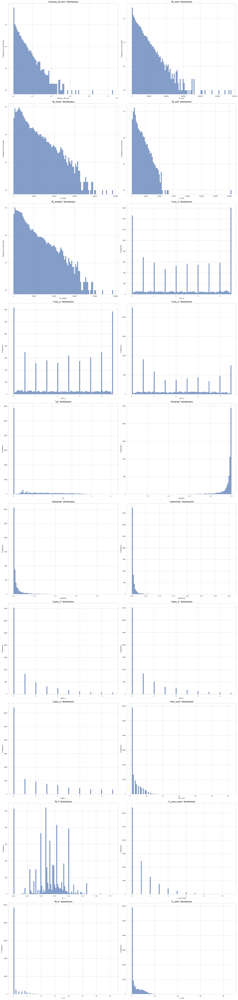

In [74]:
plot_histograms(sec_protons_up_filtered[colums_histogram], ncols=2, n_bins=100)

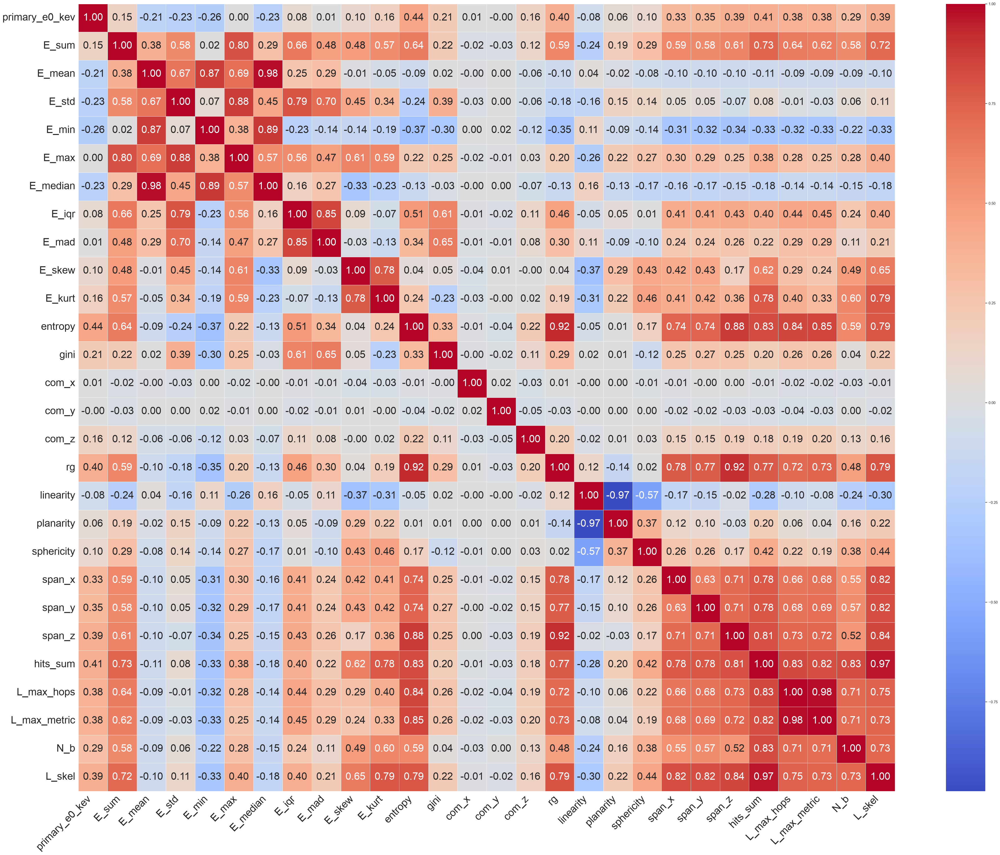

In [75]:
plot_correlation_matrix(sec_protons_up_filtered[columns_correlation], dataset_name="Secondary Protons (Upward)")

Plot the energy spectrum:

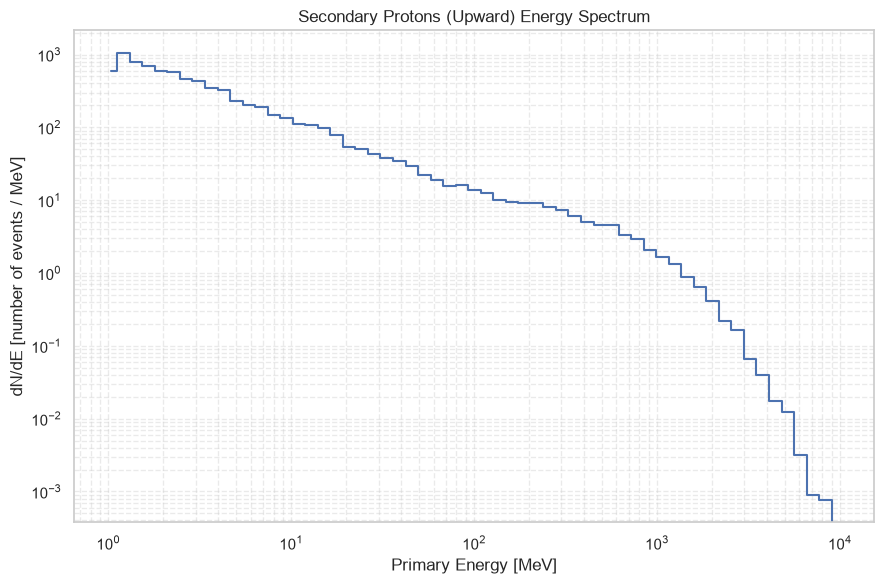

In [76]:
plot_energy_spectrum(sec_protons_up_filtered, particle_name="Secondary Protons (Upward)")

## 1.12 Terrestrial Gamma-ray Flash (TGF)

In [77]:
print("TGF dataset shape:", tgf.shape)
tgf.describe(include="all").T

TGF dataset shape: (928000, 54)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_index,928000.0,NaN,NaN,NaN,42265.742143,24209.979154,39.0,21562.0,42093.0,63120.0,89615.0
pixel_ijk,928000,194023,"[9,1,0]",4236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_e0_kev,928000.0,NaN,NaN,NaN,3103.666316,5032.648341,20.012,119.49775,691.7755,4062.3965,39996.759
n_voxels,928000.0,NaN,NaN,NaN,1.622543,1.149783,1.0,1.0,1.0,2.0,21.0
E_sum,928000.0,NaN,NaN,NaN,2215.994243,3759.548126,0.01208,101.834628,436.38101,2667.092067,37919.16146
E_mean,928000.0,NaN,NaN,NaN,1172.850195,1912.084162,0.01208,96.939925,327.62884,1486.23821,34219.35271
E_std,312344.0,NaN,NaN,NaN,2166.750402,2476.189698,0.00087,220.81807,1246.835889,3368.559444,24779.61021
E_min,928000.0,NaN,NaN,NaN,712.129134,1690.69735,0.00465,65.021107,162.37399,462.44586,34219.35271
E_max,928000.0,NaN,NaN,NaN,2010.143854,3449.444134,0.01208,99.894895,374.60865,2354.10764,35716.2426
E_median,928000.0,NaN,NaN,NaN,974.414929,1846.913108,0.01208,94.610896,256.544785,863.113062,34219.35271


In [78]:
print(f"\nThe number of missing values in each column of the TGF dataset is:")
tgf.isnull().sum()[tgf.isnull().sum() > 0]


The number of missing values in each column of the TGF dataset is:


E_std          615656
E_skew         786817
E_kurt         786817
linearity      615656
planarity      615656
sphericity     615656
corr_E_hits    840377
D_f            704510
D_f_r2         813012
f_occ          868644
dtype: int64

In [79]:
tgf_filtered = tgf.drop(columns=["f_occ", "frac_active"], )
tgf_filtered.shape

(928000, 52)

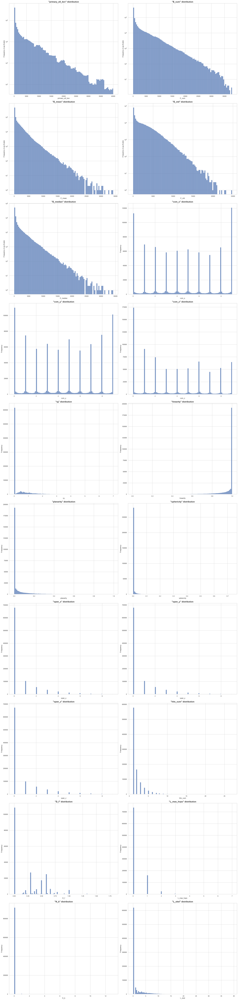

In [80]:
plot_histograms(tgf_filtered[colums_histogram], ncols=2, n_bins=100)

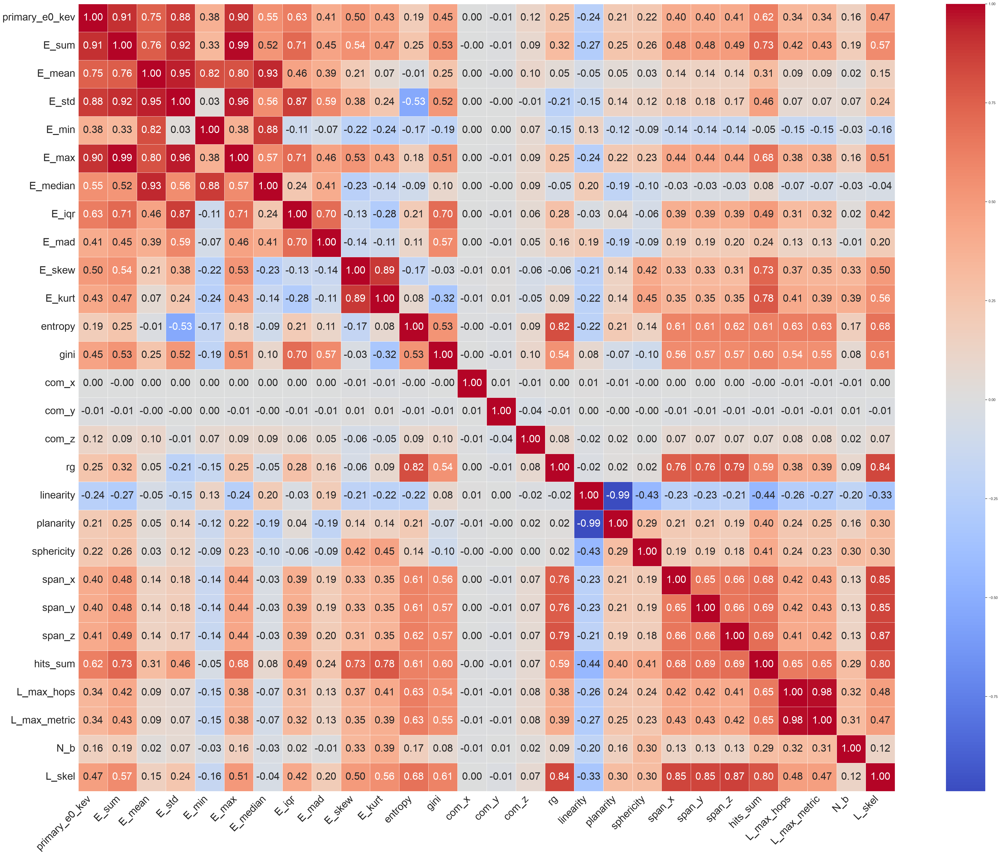

In [81]:
plot_correlation_matrix(tgf_filtered[columns_correlation], dataset_name="TGF")

Plot the energy spectrum:

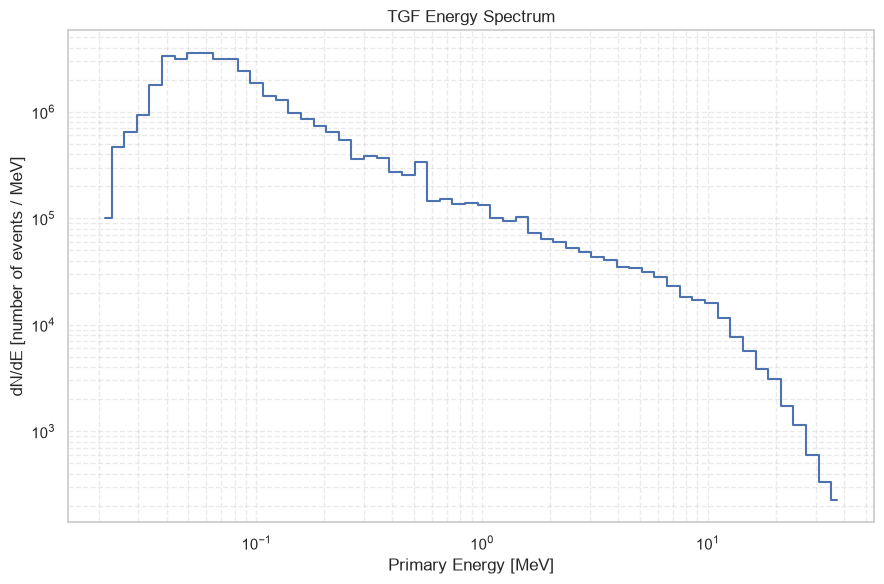

In [82]:
plot_energy_spectrum(tgf_filtered, particle_name="TGF")

# 2 - Particles comparison

In this section comparisons across different sources is done. 

## 2.1 - Energy Based Comparison

In [83]:
energy_columns = [
    # 'event_index', 
    # 'pixel_ijk', 
    'primary_e0_kev',
    # 'n_voxels', 
    'E_sum', 
    'E_mean', 
    'E_std', 
    'E_min', 
    'E_max', 
    'E_median', 
    # 'E_p10', 
    # 'E_p25', 
    # 'E_p75', 
    # 'E_p90', 
    # 'E_p95', 
    # 'E_p99', 
    'E_iqr', 
    'E_mad', 
    'E_skew', 
    'E_kurt', 
    'entropy', 
    'gini', 
    # 'n_active', 
    # 'frac_active', 
    'frac_top1', 
    'frac_top3', 
    # 'eff_E_ge_T',
]

energy_ds = ds[energy_columns + ['particle_type', "hits_sum"]]

print("Combined Energy dataset shape:", energy_ds.shape)
print("Combined Energy dataset columns:", energy_ds.columns.tolist())

# check 
print("---Combined Energy dataset particle type qta:---", energy_ds['particle_type'].value_counts())

Combined Energy dataset shape: (1296775, 17)
Combined Energy dataset columns: ['primary_e0_kev', 'E_sum', 'E_mean', 'E_std', 'E_min', 'E_max', 'E_median', 'E_iqr', 'E_mad', 'E_skew', 'E_kurt', 'entropy', 'gini', 'frac_top1', 'frac_top3', 'particle_type', 'hits_sum']
---Combined Energy dataset particle type qta:--- particle_type
TGF                         928000
CosmicPhotons               152860
AlbedoPhotons                86862
SecondaryPositrons           29089
PrimaryPositrons             19636
PrimaryProtons               18461
SecondaryProtonsUpward       11901
PrimaryAlphas                11677
SecondaryProtonsDownward     11060
AtmosphericNeutrons           9962
SecondaryElectrons            8730
PrimaryElectrons              8537
Name: count, dtype: int64


In [84]:
print("Number of missing values in each column of the combined Energy dataset:")
energy_ds.isnull().sum()[energy_ds.isnull().sum() > 0]

Number of missing values in each column of the combined Energy dataset:


E_std      857681
E_skew    1070845
E_kurt    1070845
dtype: int64

Plot the spectrum of every `particle_type`:

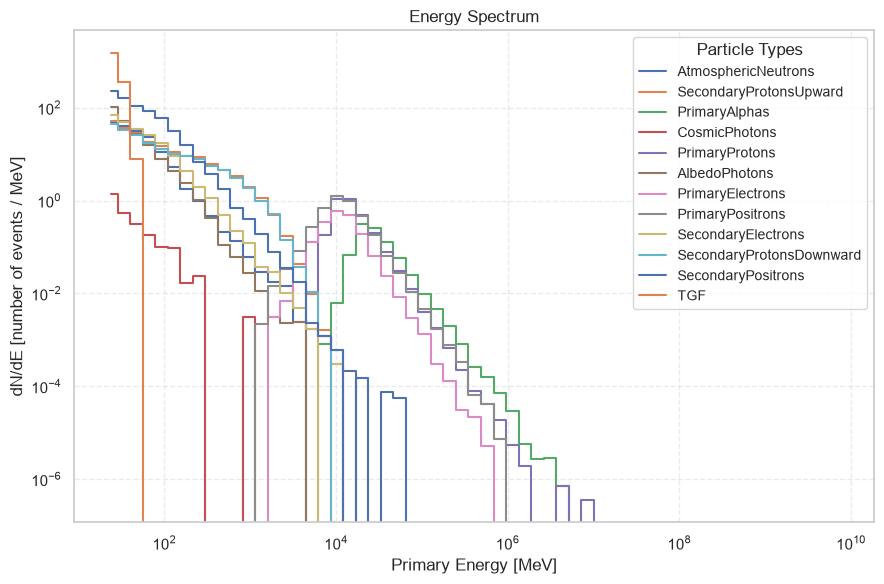

In [85]:
plt.figure(figsize=(9, 6))

primary_energy_min = ds[ds["primary_e0_kev"] > 0]["primary_e0_kev"].min()
bins = np.logspace(np.log10(primary_energy_min), np.log10(ds["primary_e0_kev"].max()), 60)  
for particle_name in ds["particle_type"].unique():
    E = ds[ds["particle_type"] == particle_name]["primary_e0_kev"].dropna()
    E = E * 1e-3  # Convert from keV to meV
    E = E[E > 0]                                   

    counts, edges = np.histogram(E, bins=bins)

    widths = np.diff(edges)
    centers = np.sqrt(edges[:-1] * edges[1:])     
    dNdE = counts / widths                         # Events per keV

    plt.step(centers, dNdE, where="mid", label=particle_name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Primary Energy [MeV]")
plt.ylabel("dN/dE [number of events / MeV]")
plt.legend(title="Particle Types", fontsize=10, title_fontsize=12)
plt.title(f"Energy Spectrum")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [86]:
## pritn a table with the number of events with primary energy > 0 for each particle type and the total number of events for each particle type
energy_stats = energy_ds.groupby("particle_type").agg(
    total_events=("primary_e0_kev", "count"),
    primary_energy_gt_zero=("primary_e0_kev", lambda x: (x > 0).sum())
).reset_index()
energy_stats["percentage_primary_energy_gt_zero"] = (energy_stats["primary_energy_gt_zero"] / energy_stats["total_events"]) * 100

energy_stats

,particle_type,total_events,primary_energy_gt_zero,percentage_primary_energy_gt_zero
0,AlbedoPhotons,86862,86814,99.944740
1,AtmosphericNeutrons,9962,9211,92.461353
2,CosmicPhotons,152860,152860,100.000000
3,PrimaryAlphas,11677,9079,77.751135
4,PrimaryElectrons,8537,7933,92.924915
5,PrimaryPositrons,19636,18029,91.816052
6,PrimaryProtons,18461,16489,89.318022
7,SecondaryElectrons,8730,8709,99.759450
8,SecondaryPositrons,29089,29022,99.769672
9,SecondaryProtonsDownward,11060,10676,96.528029


Skipped (no valid values): ['E_skew', 'E_kurt']


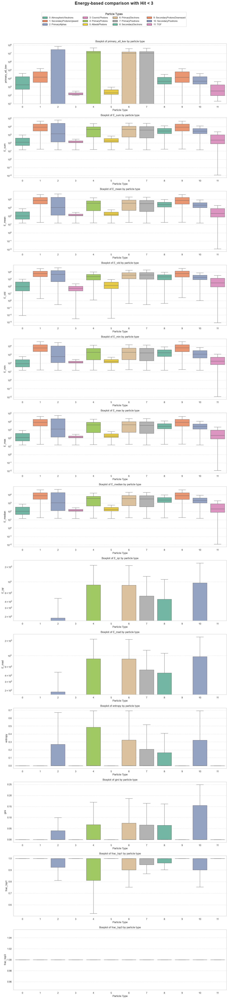

In [87]:
plot_boxplots(energy_ds[energy_ds['hits_sum'] < 3], unique_particles=energy_ds['particle_type'].unique(), title=f"Energy-based comparison with Hit < 3", showfliers=False)

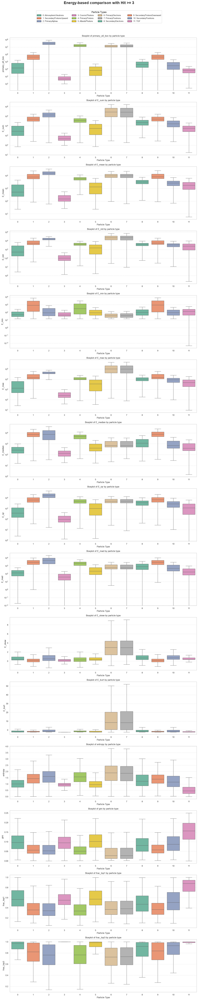

In [88]:
plot_boxplots(energy_ds[energy_ds['hits_sum'] >= 3], unique_particles=energy_ds['particle_type'].unique(), title=f"Energy-based comparison with Hit >= 3"   , showfliers=False)

## 2.2 - Geometric Based Comparison 

In [89]:
geometric_columns = [
    'com_x', 
    'com_y', 
    'com_z',    
    # 'lam1', 
    # 'lam2', 
    # 'lam3', 
    'linearity', 
    'planarity', 
    'sphericity', 
    # 'asym_x', 
    # 'asym_y', 
    # 'asym_z', 
    'span_x', 
    'span_y', 
    'span_z', 
    'rg', 
]

geometric_ds = ds[geometric_columns + ['particle_type', "hits_sum"]]
print("Combined Geometric dataset shape:", geometric_ds.shape)
print("Combined Geometric dataset columns:", geometric_ds.columns.tolist())

# # check 
# print("="*50)
# print("---Combined geometric dataset particle type qta:---", geometric_ds['particle_type'].value_counts())

print("="*50)
print("For geometric feature keep only events with hits_sum >= 3:")
geometric_ds = geometric_ds[geometric_ds['hits_sum'] >= 3]
print("Shape of the filtered Geometric dataset:", geometric_ds.shape)
print("---Filtered Geometric dataset particle type qta:---", geometric_ds['particle_type'].value_counts())

Combined Geometric dataset shape: (1296775, 12)
Combined Geometric dataset columns: ['com_x', 'com_y', 'com_z', 'linearity', 'planarity', 'sphericity', 'span_x', 'span_y', 'span_z', 'rg', 'particle_type', 'hits_sum']
For geometric feature keep only events with hits_sum >= 3:
Shape of the filtered Geometric dataset: (268674, 12)
---Filtered Geometric dataset particle type qta:--- particle_type
TGF                         183927
SecondaryPositrons           17146
PrimaryPositrons             14694
PrimaryProtons               12751
AlbedoPhotons                 8790
PrimaryAlphas                 7630
PrimaryElectrons              6520
SecondaryProtonsUpward        4652
SecondaryProtonsDownward      4314
SecondaryElectrons            4207
AtmosphericNeutrons           2118
CosmicPhotons                 1925
Name: count, dtype: int64


In [90]:
print("Number of missing values in each column of the combined Geometric dataset:")
geometric_ds.isnull().sum()[geometric_ds.isnull().sum() > 0]

Number of missing values in each column of the combined Geometric dataset:


linearity     11034
planarity     11034
sphericity    11034
dtype: int64

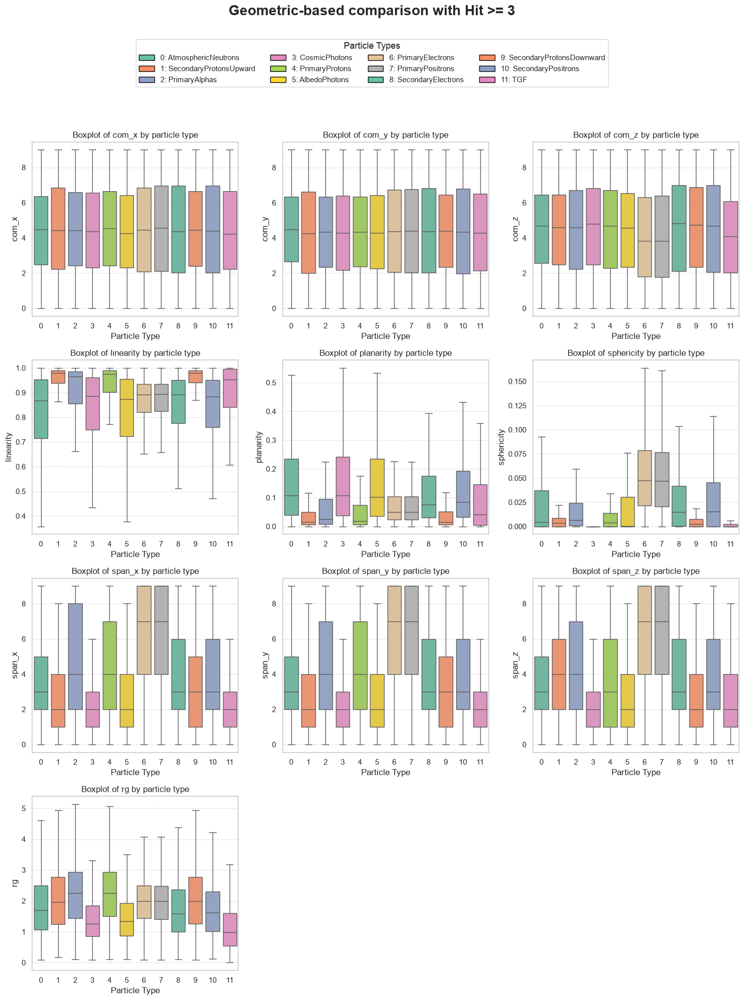

In [91]:
plot_boxplots(geometric_ds, unique_particles=geometric_ds['particle_type'].unique(), title=f"Geometric-based comparison with Hit >= 3", ncols=3, showfliers=False)

## 2.3 - Hits Based Comparison

In [92]:
hits_columns = [
    'hits_sum', 
    'hits_mean_active', 
    'corr_E_hits', 
]

hits_ds = ds[hits_columns + ['particle_type']]
print("Combined Hits dataset shape:", hits_ds.shape)
print("Combined Hits dataset columns:", hits_ds.columns.tolist())

# check 
print("="*50)
print("---Combined Hits dataset particle type qta:---", hits_ds['particle_type'].value_counts())

Combined Hits dataset shape: (1296775, 4)
Combined Hits dataset columns: ['hits_sum', 'hits_mean_active', 'corr_E_hits', 'particle_type']
---Combined Hits dataset particle type qta:--- particle_type
TGF                         928000
CosmicPhotons               152860
AlbedoPhotons                86862
SecondaryPositrons           29089
PrimaryPositrons             19636
PrimaryProtons               18461
SecondaryProtonsUpward       11901
PrimaryAlphas                11677
SecondaryProtonsDownward     11060
AtmosphericNeutrons           9962
SecondaryElectrons            8730
PrimaryElectrons              8537
Name: count, dtype: int64


In [93]:
print("Number of missing values in each column of the combined Hits dataset:")
hits_ds.isnull().sum()[hits_ds.isnull().sum() > 0]

# see if mean_hits has only a unique value for each particle type
print("\nCheck if hits_mean_active has only a unique value for each particle type:")
hits_mean_active_unique = hits_ds.groupby('particle_type')['hits_mean_active'].nunique()
print(hits_mean_active_unique)

Number of missing values in each column of the combined Hits dataset:

Check if hits_mean_active has only a unique value for each particle type:
particle_type
AlbedoPhotons                 1
AtmosphericNeutrons           1
CosmicPhotons                 1
PrimaryAlphas                 1
PrimaryElectrons              1
PrimaryPositrons              1
PrimaryProtons                1
SecondaryElectrons            1
SecondaryPositrons            1
SecondaryProtonsDownward      1
SecondaryProtonsUpward        1
TGF                         106
Name: hits_mean_active, dtype: int64


We can notice that the hits_mean_active feature is singled value almost every time so we can drop it

In [94]:
hits_ds = hits_ds.drop(columns=["hits_mean_active", "corr_E_hits"])

In [95]:
summary = (
    hits_ds.groupby("particle_type", dropna=False)
      .agg(
          tot_event=("particle_type", "size"),
          mean_hits=("hits_sum", "mean"),
          median_hits=("hits_sum", "median"),
          hits_1=("hits_sum", lambda s: (s == 1).sum()),
          hits_2=("hits_sum", lambda s: (s == 2).sum()),
          hits_3_or_more=("hits_sum", lambda s: (s >= 3).sum()),
          hits_10_or_more=("hits_sum", lambda s: (s >= 10).sum()),
          hits_20_or_more=("hits_sum", lambda s: (s >= 20).sum()),
      )
      .reset_index()
      .rename(columns={"particle_type": "type"})
)

percentage_columns = [
    "hits_1",
    "hits_2",
    "hits_3_or_more",
    "hits_10_or_more",
    "hits_20_or_more",
]

summary[percentage_columns] = (
    summary[percentage_columns]
    .div(summary["tot_event"], axis=0)
    .mul(100)
)

summary[percentage_columns] = summary[percentage_columns].round(3)
summary["mean_hits"] = summary["mean_hits"].round(2)

print("Summary of hits distribution by particle type in percent:")
summary

Summary of hits distribution by particle type in percent:


,type,tot_event,mean_hits,median_hits,hits_1,hits_2,hits_3_or_more,hits_10_or_more,hits_20_or_more
0,AlbedoPhotons,86862,1.59,1.0,75.599,14.281,10.119,1.108,0.197
1,AtmosphericNeutrons,9962,2.13,1.0,62.628,16.111,21.261,1.978,0.231
2,CosmicPhotons,152860,1.12,1.0,89.936,8.805,1.259,0.007,0.001
3,PrimaryAlphas,11677,14.02,5.0,23.859,10.799,65.342,29.836,13.026
4,PrimaryElectrons,8537,34.44,16.0,15.661,7.965,76.373,57.678,46.410
5,PrimaryPositrons,19636,33.55,14.0,17.295,7.873,74.832,56.167,44.495
6,PrimaryProtons,18461,9.42,5.0,19.365,11.565,69.070,19.733,8.369
7,SecondaryElectrons,8730,5.19,2.0,35.899,15.911,48.190,15.418,4.914
8,SecondaryPositrons,29089,5.80,3.0,24.157,16.900,58.943,17.092,5.363
9,SecondaryProtonsDownward,11060,3.31,2.0,49.602,11.392,39.005,5.931,0.814


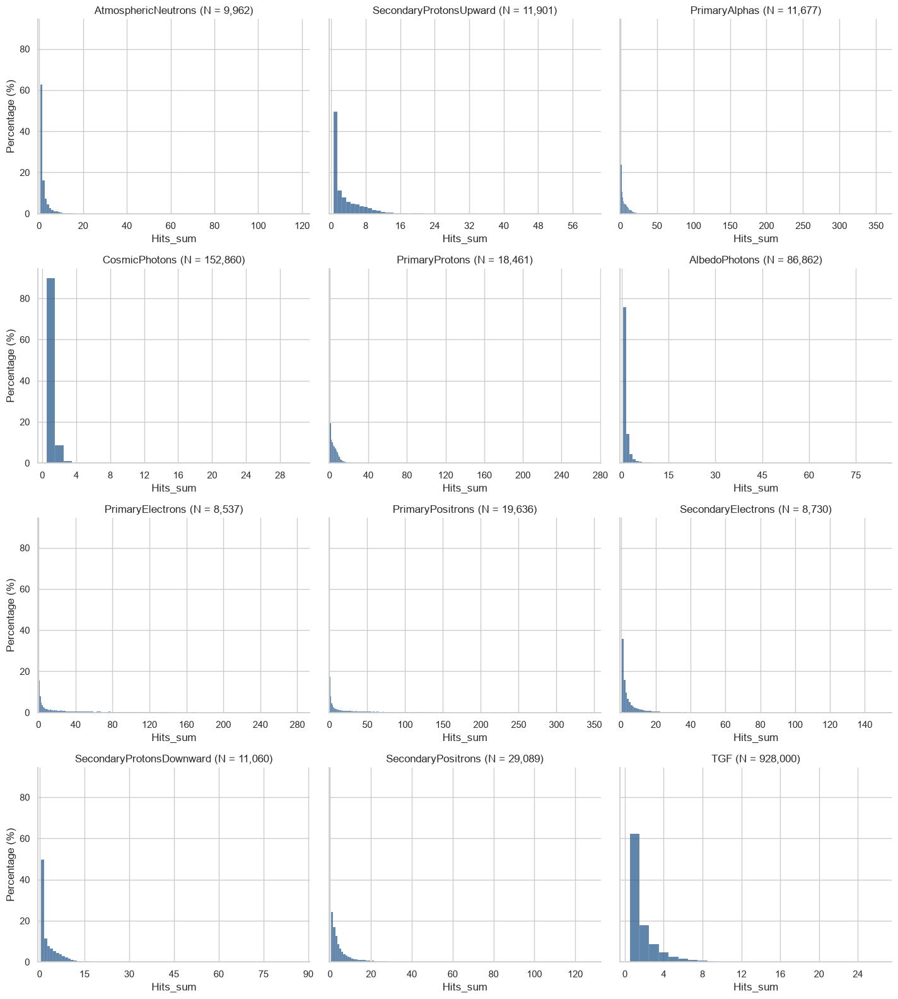

In [96]:
sns.set_style("whitegrid")
hits_plot = hits_ds.copy()
counts = hits_ds["particle_type"].value_counts()

g = sns.displot(
    data=hits_plot,
    x="hits_sum",
    col="particle_type",
    col_wrap=3,
    discrete=True,
    stat="percent",
    common_norm=False,
    height=4,
    aspect=1.2,
    color="#2b5c8f",
    facet_kws={"sharex": False, "sharey": True},
)

g.set_axis_labels("", "Percentage (%)")

for ax, particle in zip(g.axes.flat, g.col_names):
    max_hits = int(hits_plot.loc[hits_plot["particle_type"] == particle, "hits_sum"].max())

    ax.set_title(f"{particle} (N = {counts[particle]:,})")
    ax.set_xlabel("Hits_sum")
    ax.set_xlim(-0.5, max_hits + 0.5)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
    ax.tick_params(axis="x", labelbottom=True)

plt.tight_layout()
plt.show()

Plot the number of events remaining for `hits_sum` >= X

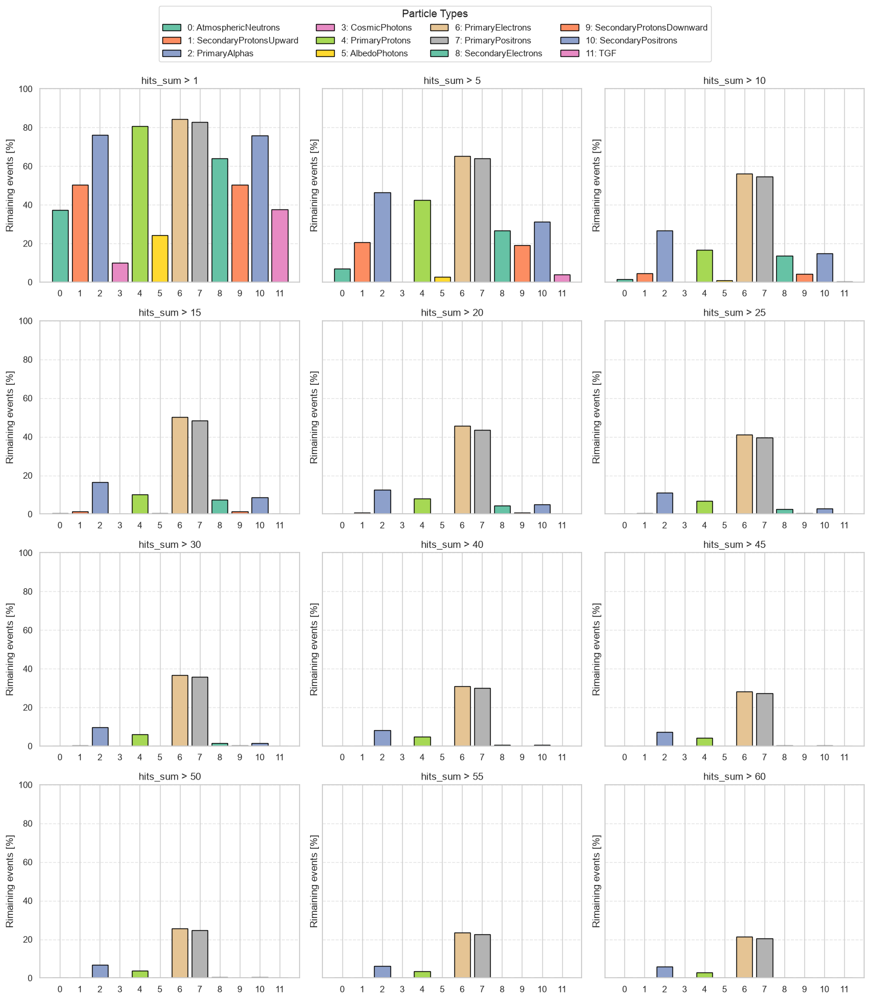

In [97]:
hit_col = "hits_sum"
thresholds = [1, 5, 10, 15, 20, 25, 30, 40, 45, 50, 55, 60]
classes = hits_ds["particle_type"].unique()
particle_to_id = {name: i for i, name in enumerate(classes)}
palette = sns.color_palette("Set2", n_colors=len(classes))

totals = ds["particle_type"].value_counts().reindex(classes)
frac = {}
for t in thresholds:
    kept = ds.loc[ds[hit_col] > t, "particle_type"].value_counts().reindex(classes, fill_value=0)
    frac[t] = kept / totals * 100

ncols = 3
nrows = int(np.ceil(len(thresholds) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharey=True)
axes = axes.flatten()

for ax, t in zip(axes, thresholds):
    ax.bar(range(len(classes)), frac[t].values, color=palette, edgecolor="black")
    ax.set_title(f"{hit_col} > {t}")
    ax.set_ylabel("Rimaining events [%]")
    ax.set_ylim(0, 100)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels([particle_to_id[n] for n in classes])
    ax.grid(True, linestyle="--", alpha=0.5, axis="y")

for ax in axes[len(thresholds):]:
    ax.axis("off")

handles = [
    Patch(facecolor=palette[k], edgecolor="black", label=f"{k}: {name}")
    for k, name in enumerate(classes)
]
fig.legend(
    handles=handles,
    title="Particle Types",
    title_fontsize=13,
    fontsize=11,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=min(4, len(classes)),
    frameon=True,
)

plt.tight_layout()
plt.show()

## 2.4 - Topological Comparison

In [98]:
topological_columns = [
    'D_f', 
    'D_f_r2', 
    #'f_occ', 
    'L_max_hops', 
    'L_max_metric', 
    'N_b', 
    'L_skel'
]

topological_ds = ds[topological_columns + ['particle_type', "hits_sum"]]
print("Combined Topological dataset shape:", topological_ds.shape)
print("Combined Topological dataset columns:", topological_ds.columns.tolist())

print("="*50)
print("For topological feature keep only events with hits_sum >= 3:")
topological_ds = topological_ds[topological_ds['hits_sum'] >= 3]
print("Shape of the filtered Topological dataset:", topological_ds.shape)
print("---Filtered Topological dataset particle type qta:---", topological_ds['particle_type'].value_counts())

Combined Topological dataset shape: (1296775, 8)
Combined Topological dataset columns: ['D_f', 'D_f_r2', 'L_max_hops', 'L_max_metric', 'N_b', 'L_skel', 'particle_type', 'hits_sum']
For topological feature keep only events with hits_sum >= 3:
Shape of the filtered Topological dataset: (268674, 8)
---Filtered Topological dataset particle type qta:--- particle_type
TGF                         183927
SecondaryPositrons           17146
PrimaryPositrons             14694
PrimaryProtons               12751
AlbedoPhotons                 8790
PrimaryAlphas                 7630
PrimaryElectrons              6520
SecondaryProtonsUpward        4652
SecondaryProtonsDownward      4314
SecondaryElectrons            4207
AtmosphericNeutrons           2118
CosmicPhotons                 1925
Name: count, dtype: int64


In [99]:
print("Number of missing values in each column of the combined Hits dataset:")
topological_ds.isnull().sum()[topological_ds.isnull().sum() > 0]

Number of missing values in each column of the combined Hits dataset:


D_f       35192
D_f_r2    75609
dtype: int64

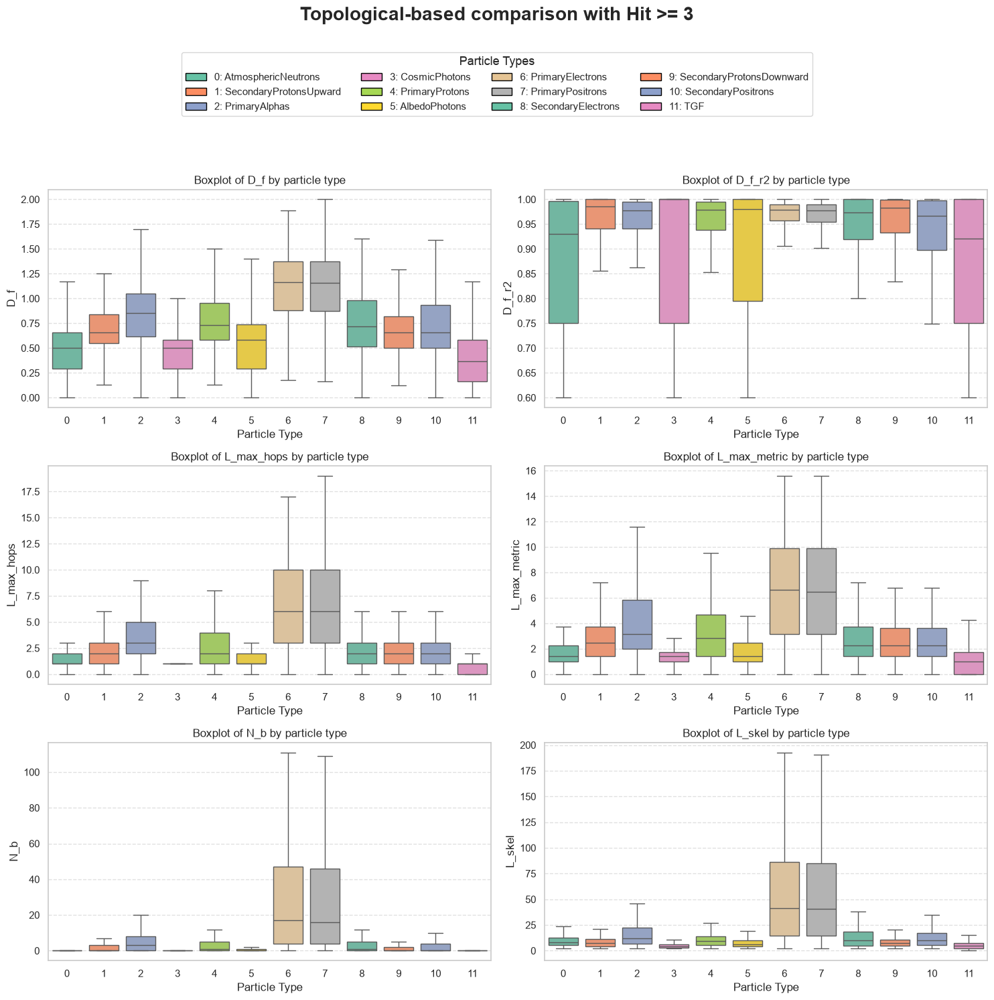

In [100]:
plot_boxplots(topological_ds, unique_particles=topological_ds['particle_type'].unique(), title=f"Topological-based comparison with Hit >= 3", ncols=2, showfliers=False)

# 3 - Feature Evolution wrt number of hits

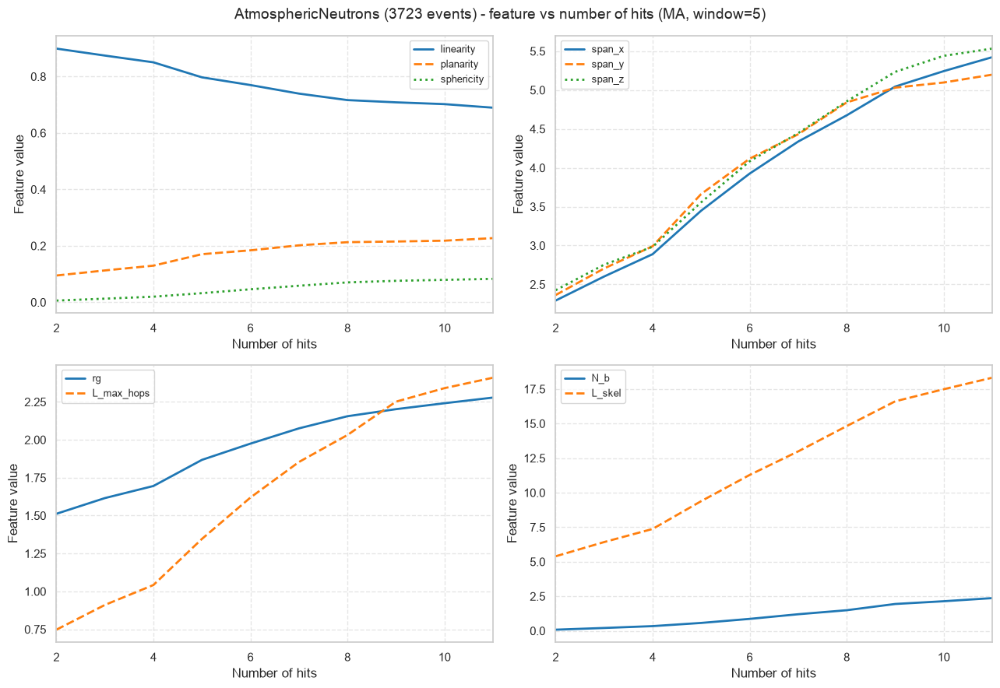

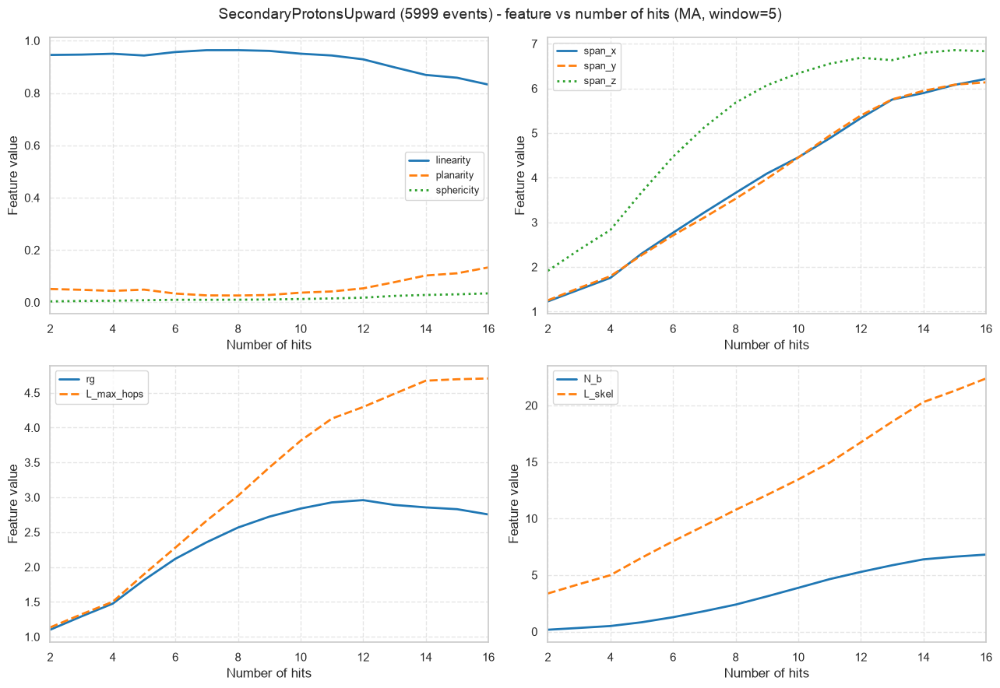

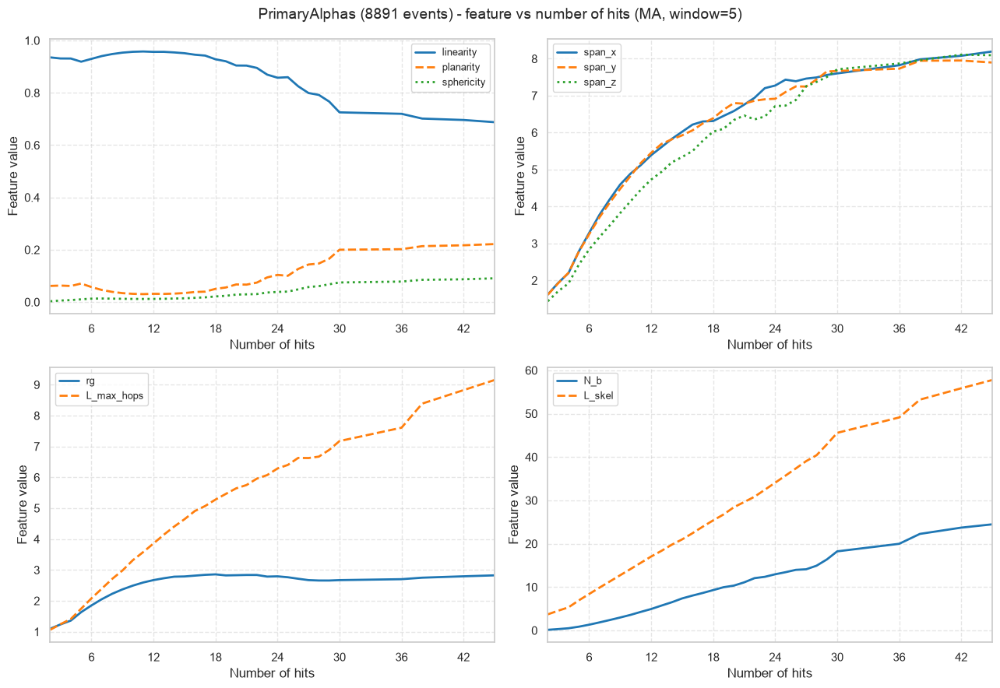

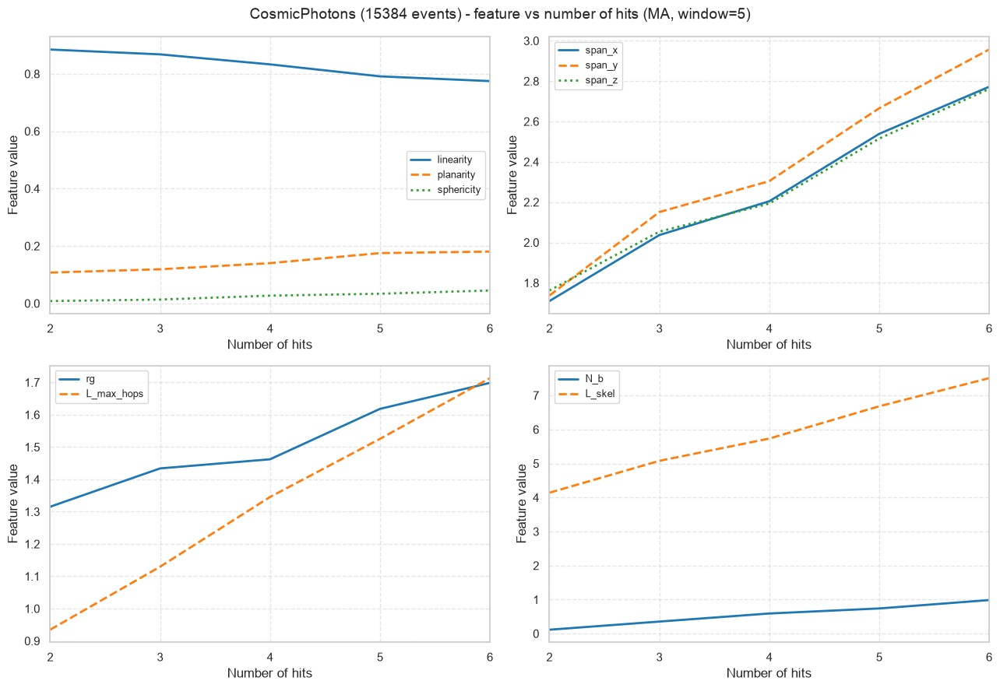

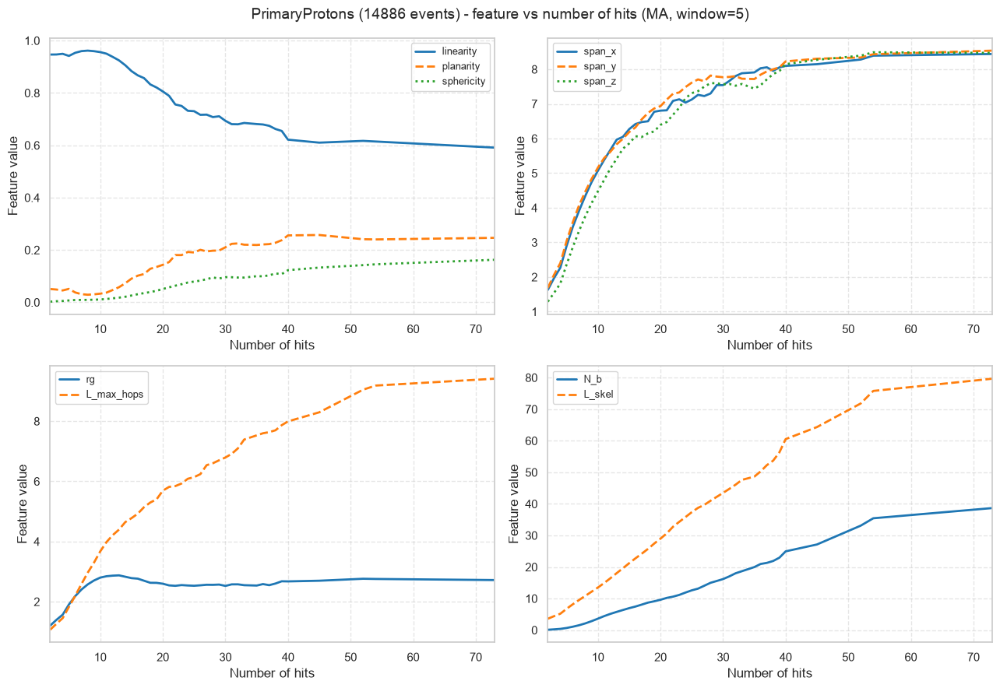

...

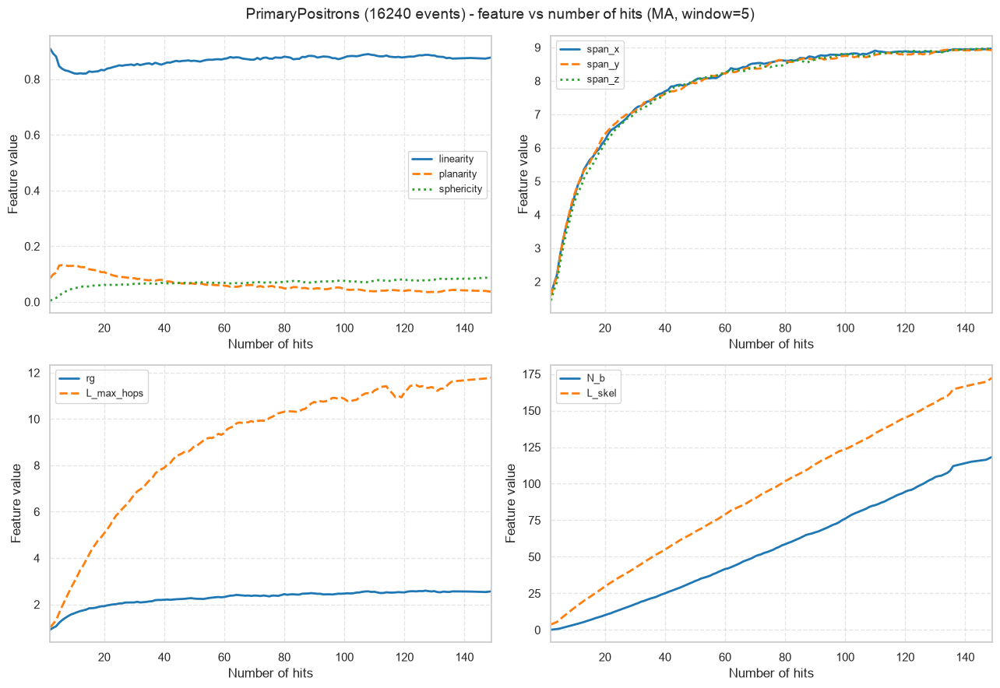

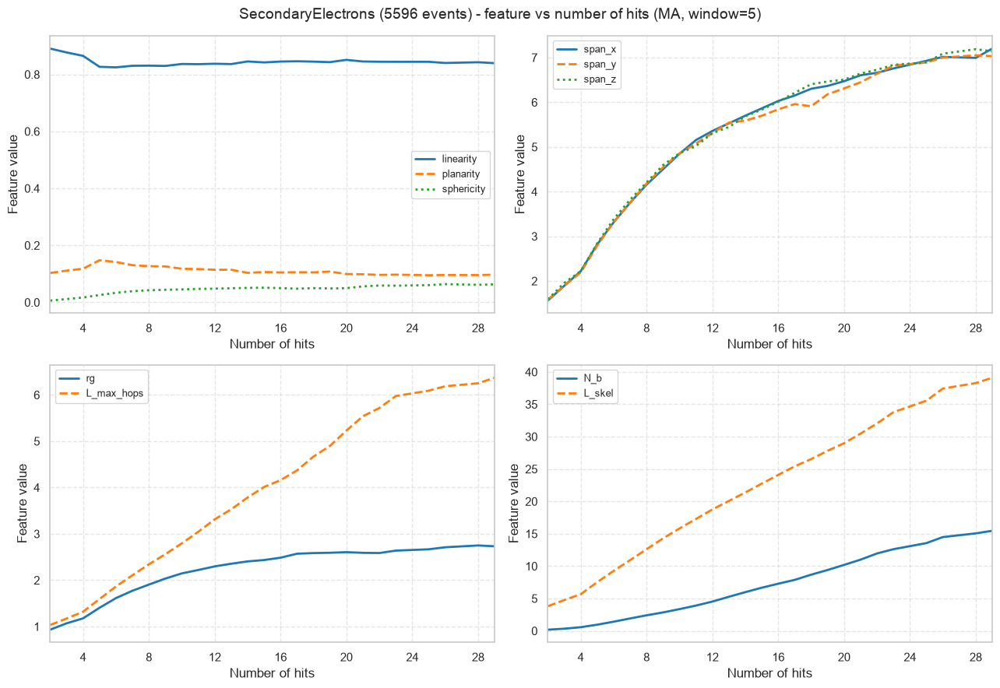

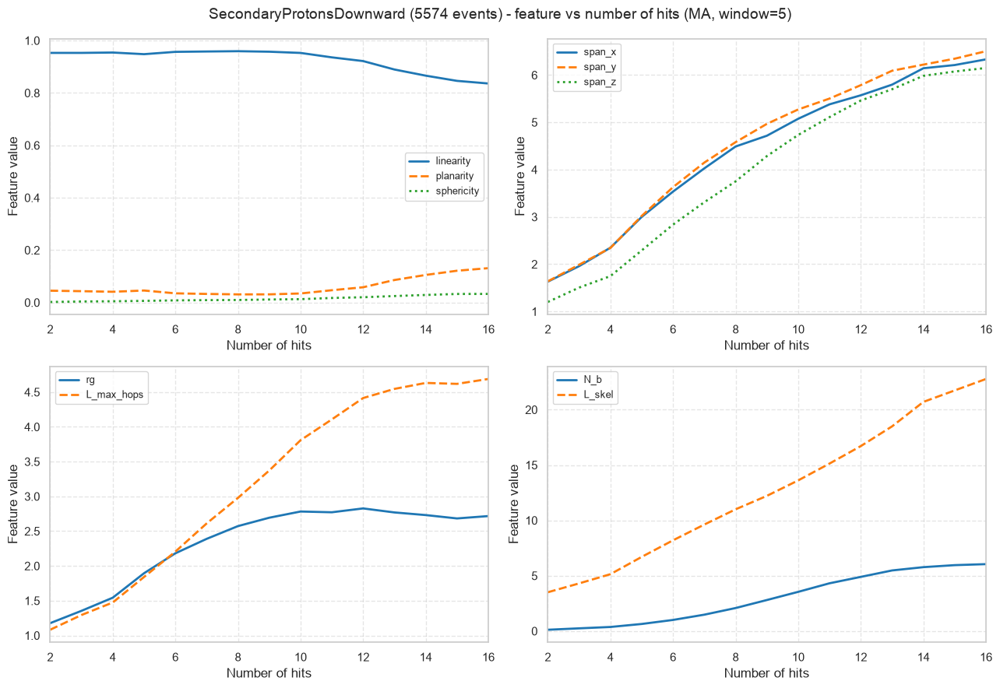

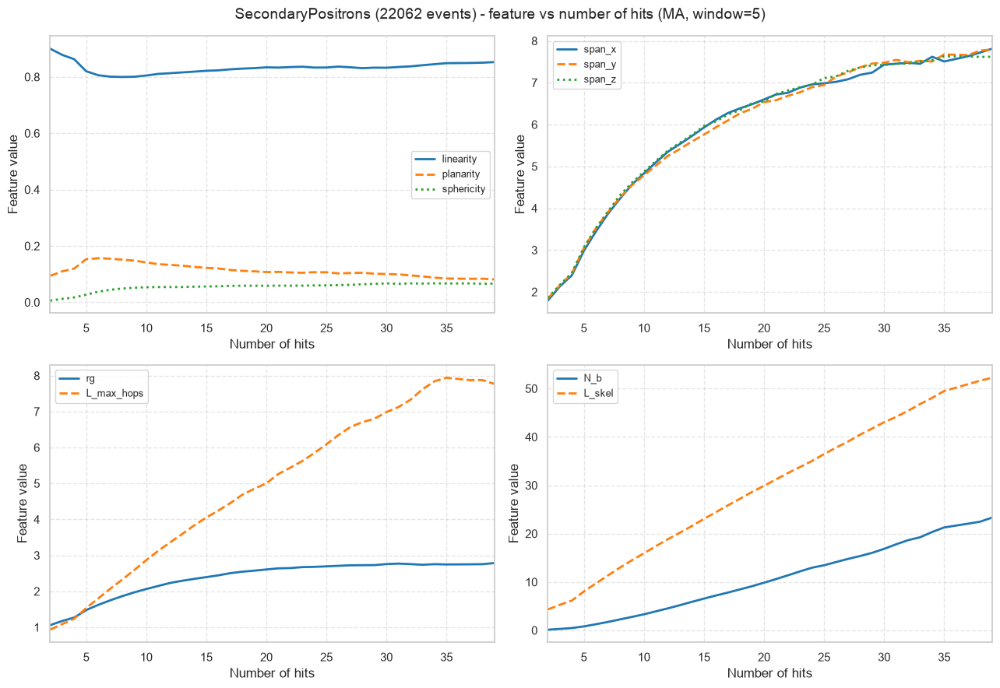

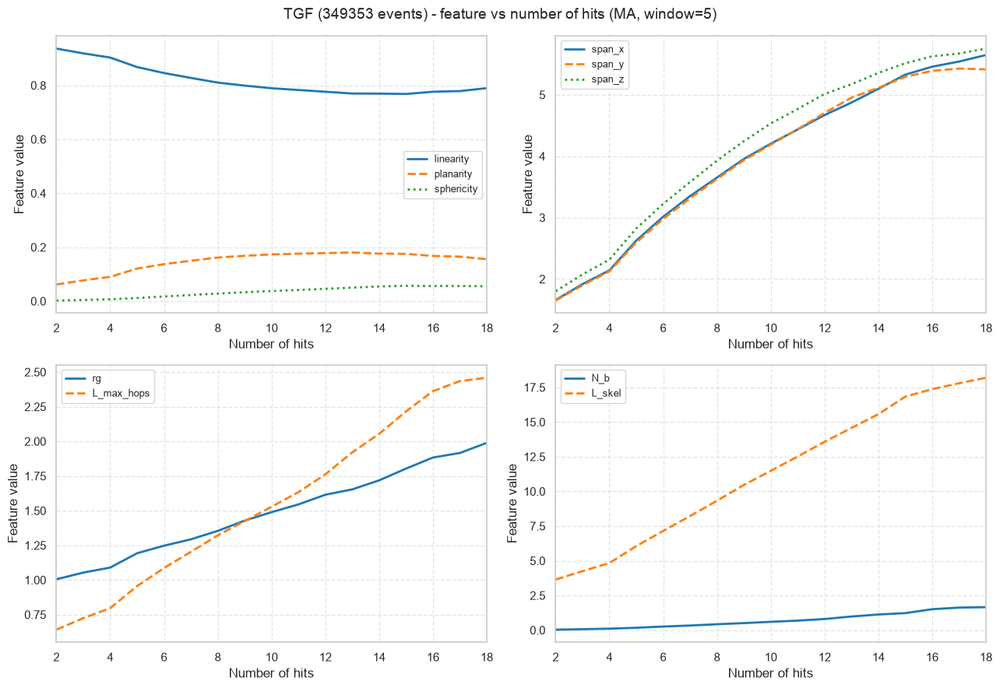

In [101]:
groups = {
    "Shape": ["linearity", "planarity", "sphericity"],
    "Span": ["span_x", "span_y", "span_z"],
    "Extent": ["rg", "L_max_hops", ], #"L_max_metric"],
    "Topology": ["N_b", "L_skel"],
}

plot_feature_evolution(ds, classes=ds["particle_type"].unique(), hit_col="hits_sum", groups=groups, normalize=False, min_hits=2, min_events=20, window=5, ncols=2, out_dir="pdf", save_plots=False)